# Robust Bank Account Fraud Detection Under Temporal Distribution Shift
**BT4012 Fraud Analytics — Group 21**

**Primary question:** How do temporal changes in fraud prevalence and predictive feature relationships affect the future performance of bank account fraud detection models?

**Supporting questions**
1. Which classifier best maintains fraud-detection performance on future applications?
2. How does performance differ under changes in fraud prevalence (Variant IV) compared with changes in feature predictiveness (Variant V)?
3. How do these changes affect false-positive rates and fraud recall for applicants aged ≤50 vs >50?

**Design summary**

| Item | Choice |
|---|---|
| Datasets | Base, Variant IV, Variant V (BAF suite, NeurIPS 2022), each a separate experiment |
| Time split | Train: months 0–3 · Validation: months 4–5 · Out-of-time test: months 6–7 (untouched until evaluation) |
| Models | Logistic regression, decision tree, random forest, LightGBM, XGBoost (class-weighted) |
| Tuning | Optuna (seeded TPE) on the Base validation period, then fixed for Variants IV and V |
| Ranking metrics | Average precision (AP) **and** recall at 5% FPR (prevalence-independent) |
| Operating settings | **Fixed threshold** (5% FPR on validation, applied unchanged) — primary for the age comparison; **fixed review capacity** (top 1% / 5% of each month) — secondary |

**Data:** download `Base.csv`, `Variant IV.csv` and `Variant V.csv` from the [Kaggle BAF dataset](https://www.kaggle.com/datasets/sgpjesus/bank-account-fraud-dataset-neurips-2022) into the folder set in `DATA_DIR` below.

## 0. Setup

In [1]:
import os
import time
import json
import warnings
from itertools import product, combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import lightgbm as lgb
import xgboost as xgb
import optuna

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# results (random forest especially) shift slightly between library versions, so log them
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| lightgbm", lgb.__version__, "| xgboost", xgb.__version__, "| optuna", optuna.__version__)

/private/tmp/claude-501/-Users-lihanlin-Developer-Capstone-CDG/b22d81ba-e849-46e5-8496-c1392a65b978/scratchpad/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


numpy 2.5.5 | pandas 3.1.1 | sklearn 1.9.1 | lightgbm 4.7.0 | xgboost 3.4.1 | optuna 5.1.0


In [2]:
DATA_DIR = "data"
DATASET_FILES = {"Base": "Base.csv", "Variant IV": "Variant IV.csv", "Variant V": "Variant V.csv"}
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

TARGET = "fraud_bool"
MONTH = "month"
AGE = "customer_age"
AGE_CUTOFF = 50
INCLUDE_AGE_FEATURE = True

TRAIN_MONTHS = [0, 1, 2, 3]
VAL_MONTHS = [4, 5]
TEST_MONTHS = [6, 7]

TARGET_FPR = 0.05                  # operating point used in the BAF paper
REVIEW_CAPACITIES = [0.01, 0.05]   # share of each month's applications sent for review

SAMPLE_FRAC = None   # e.g. 0.2 for a quick run
RANDOM_STATE = 42
N_THREADS = 4        # boosting results depend on thread count, so pin it

# Optuna trials per model. the boosting models get more because they have more knobs
N_TRIALS = {"Logistic Regression": 20, "Decision Tree": 30, "Random Forest": 20,
            "LightGBM": 40, "XGBoost": 40}

CAT_COLS = ["payment_type", "employment_status", "housing_status", "source", "device_os"]
# BAF codes missing values as -1 in these columns...
MISSING_NEG1 = ["prev_address_months_count", "current_address_months_count", "bank_months_count",
                "session_length_in_minutes", "device_distinct_emails_8w"]
# ...and as any negative value in this one
MISSING_NEGATIVE = ["intended_balcon_amount"]

## 1. Load data
Missing-value sentinels are converted to `NaN` so they can be imputed and flagged. Numeric columns are downcast to save memory (3 × 1M rows).

In [3]:
datasets = {}
for name, file in DATASET_FILES.items():
    df = pd.read_csv(os.path.join(DATA_DIR, file))

    if SAMPLE_FRAC:
        # stratify so each month keeps its fraud rate
        df = df.groupby([MONTH, TARGET], group_keys=False).sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE)
        df = df.sort_index()

    # 3 x 1M rows: downcast to keep memory manageable
    for col in df.columns:
        if df[col].dtype == "float64":
            df[col] = df[col].astype("float32")
        elif df[col].dtype == "int64":
            df[col] = pd.to_numeric(df[col], downcast="integer")

    for col in MISSING_NEG1:
        df[col] = df[col].replace(-1, np.nan).astype("float32")
    for col in MISSING_NEGATIVE:
        df[col] = df[col].where(df[col] >= 0).astype("float32")

    df["age_group"] = np.where(df[AGE] > AGE_CUTOFF, ">50", "<=50")

    df["split"] = "test"
    df.loc[df[MONTH].isin(TRAIN_MONTHS), "split"] = "train"
    df.loc[df[MONTH].isin(VAL_MONTHS), "split"] = "val"

    df = df.reset_index(drop=True)
    datasets[name] = df
    print(name, "| rows:", len(df), "| cols:", df.shape[1], "| fraud rate:", round(df[TARGET].mean() * 100, 3), "%")

Base | rows: 1000000 | cols: 34 | fraud rate: 1.103 %


Variant IV | rows: 1000000 | cols: 34 | fraud rate: 1.103 %


Variant V | rows: 1000000 | cols: 36 | fraud rate: 1.103 %


## 2. Exploratory analysis
### 2.1 Overview and class imbalance

In [4]:
overview_rows = []
for name, df in datasets.items():
    overview_rows.append({
        "dataset": name,
        "rows": len(df),
        "frauds": df[TARGET].sum(),
        "fraud_rate": df[TARGET].mean(),
        "share_age_>50": (df["age_group"] == ">50").mean(),
        "train_rows": (df["split"] == "train").sum(),
        "val_rows": (df["split"] == "val").sum(),
        "test_rows": (df["split"] == "test").sum(),
    })
overview = pd.DataFrame(overview_rows).set_index("dataset")
overview

,rows,frauds,fraud_rate,share_age_>50,train_rows,val_rows,test_rows
dataset,,,,,,,
Base,1000000,11029,0.0110,0.0427,547975,247014,205011
Variant IV,1000000,11030,0.0110,0.1230,484462,273866,241672
Variant V,1000000,11030,0.0110,0.1227,484464,273864,241672


In [5]:
missing_share = pd.DataFrame()
for name, df in datasets.items():
    missing_share[name] = df[MISSING_NEG1 + MISSING_NEGATIVE].isna().mean()
print("Share of missing values")
display(missing_share)

for name, df in datasets.items():
    constant_cols = [col for col in df.columns if df[col].nunique(dropna=False) <= 1]
    print(name, "constant columns:", constant_cols)

Share of missing values


,Base,Variant IV,Variant V
prev_address_months_count,0.7129,0.7618,0.7617
current_address_months_count,0.0043,0.0035,0.0034
bank_months_count,0.2536,0.2472,0.2469
session_length_in_minutes,0.0020,0.0023,0.0022
device_distinct_emails_8w,0.0004,0.0003,0.0003
intended_balcon_amount,0.7425,0.7517,0.7511


Base constant columns: ['device_fraud_count']


Variant IV constant columns: ['device_fraud_count']


Variant V constant columns: ['device_fraud_count']


### 2.2 Monthly fraud prevalence, overall and by age group
This is where Variant IV should differ: the >50 group has a much higher fraud rate in months 0–5; in months 6–7 the gap between the groups narrows sharply but does not close completely.

Base                Variant IV                Variant V         \
age_group   <=50    >50 overall       <=50    >50 overall      <=50    >50   
month                                                                        
0         0.0101 0.0360  0.0113     0.0093 0.0282  0.0117    0.0109 0.0172   
1         0.0086 0.0268  0.0094     0.0072 0.0209  0.0089    0.0083 0.0134   
2         0.0079 0.0289  0.0087     0.0060 0.0177  0.0073    0.0067 0.0120   
3         0.0082 0.0312  0.0092     0.0110 0.0329  0.0136    0.0128 0.0198   
4         0.0101 0.0376  0.0114     0.0129 0.0348  0.0157    0.0150 0.0203   
5         0.0109 0.0340  0.0118     0.0071 0.0230  0.0091    0.0085 0.0136   
6         0.0122 0.0382  0.0134     0.0115 0.0172  0.0123    0.0114 0.0181   
7         0.0135 0.0551  0.0147     0.0087 0.0139  0.0093    0.0086 0.0142   

                   
age_group overall  
month              
0          0.0117  
1          0.0089  
2          0.0073  
3          0.0136  
4          0.0157  
5          0.0091  
6          0.0123  
7          0.0093

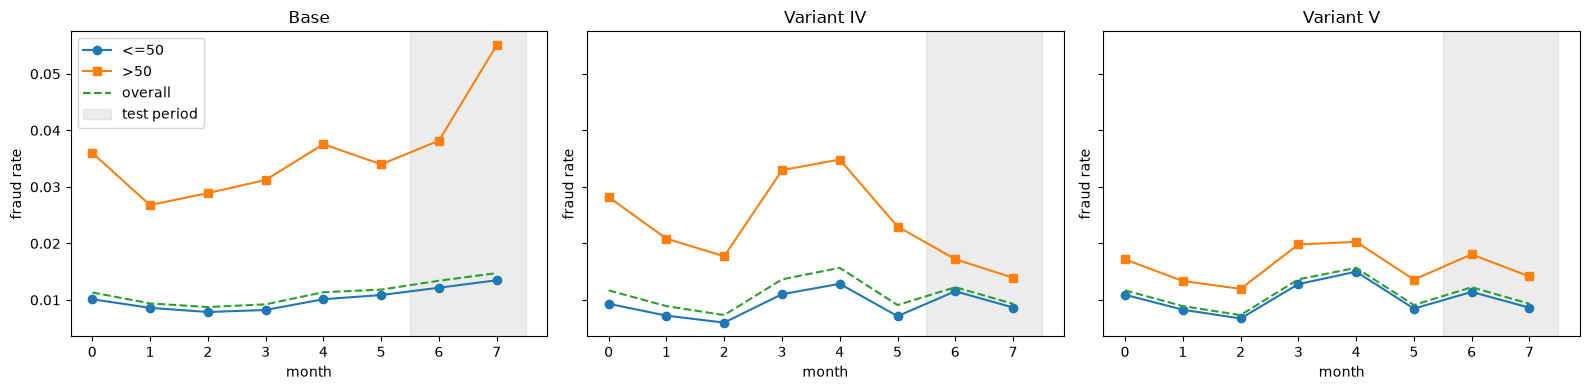

In [6]:
monthly_fraud = {}
for name, df in datasets.items():
    rates = df.groupby([MONTH, "age_group"])[TARGET].mean().unstack()
    rates["overall"] = df.groupby(MONTH)[TARGET].mean()
    monthly_fraud[name] = rates
display(pd.concat(monthly_fraud, axis=1).round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, name in zip(axes, datasets):
    rates = monthly_fraud[name]
    ax.plot(rates.index, rates["<=50"], "-o", label="<=50")
    ax.plot(rates.index, rates[">50"], "-s", label=">50")
    ax.plot(rates.index, rates["overall"], "--", label="overall")
    ax.axvspan(TEST_MONTHS[0] - 0.5, TEST_MONTHS[-1] + 0.5, color="grey", alpha=0.15, label="test period")
    ax.set_title(name)
    ax.set_xlabel("month")
    ax.set_ylabel("fraud rate")
axes[0].legend()
plt.tight_layout()
fig.savefig(OUT_DIR + "/fig1_prevalence.png", dpi=200, bbox_inches="tight")
plt.show()

### 2.3 Feature distributions (Base, fraud vs non-fraud)

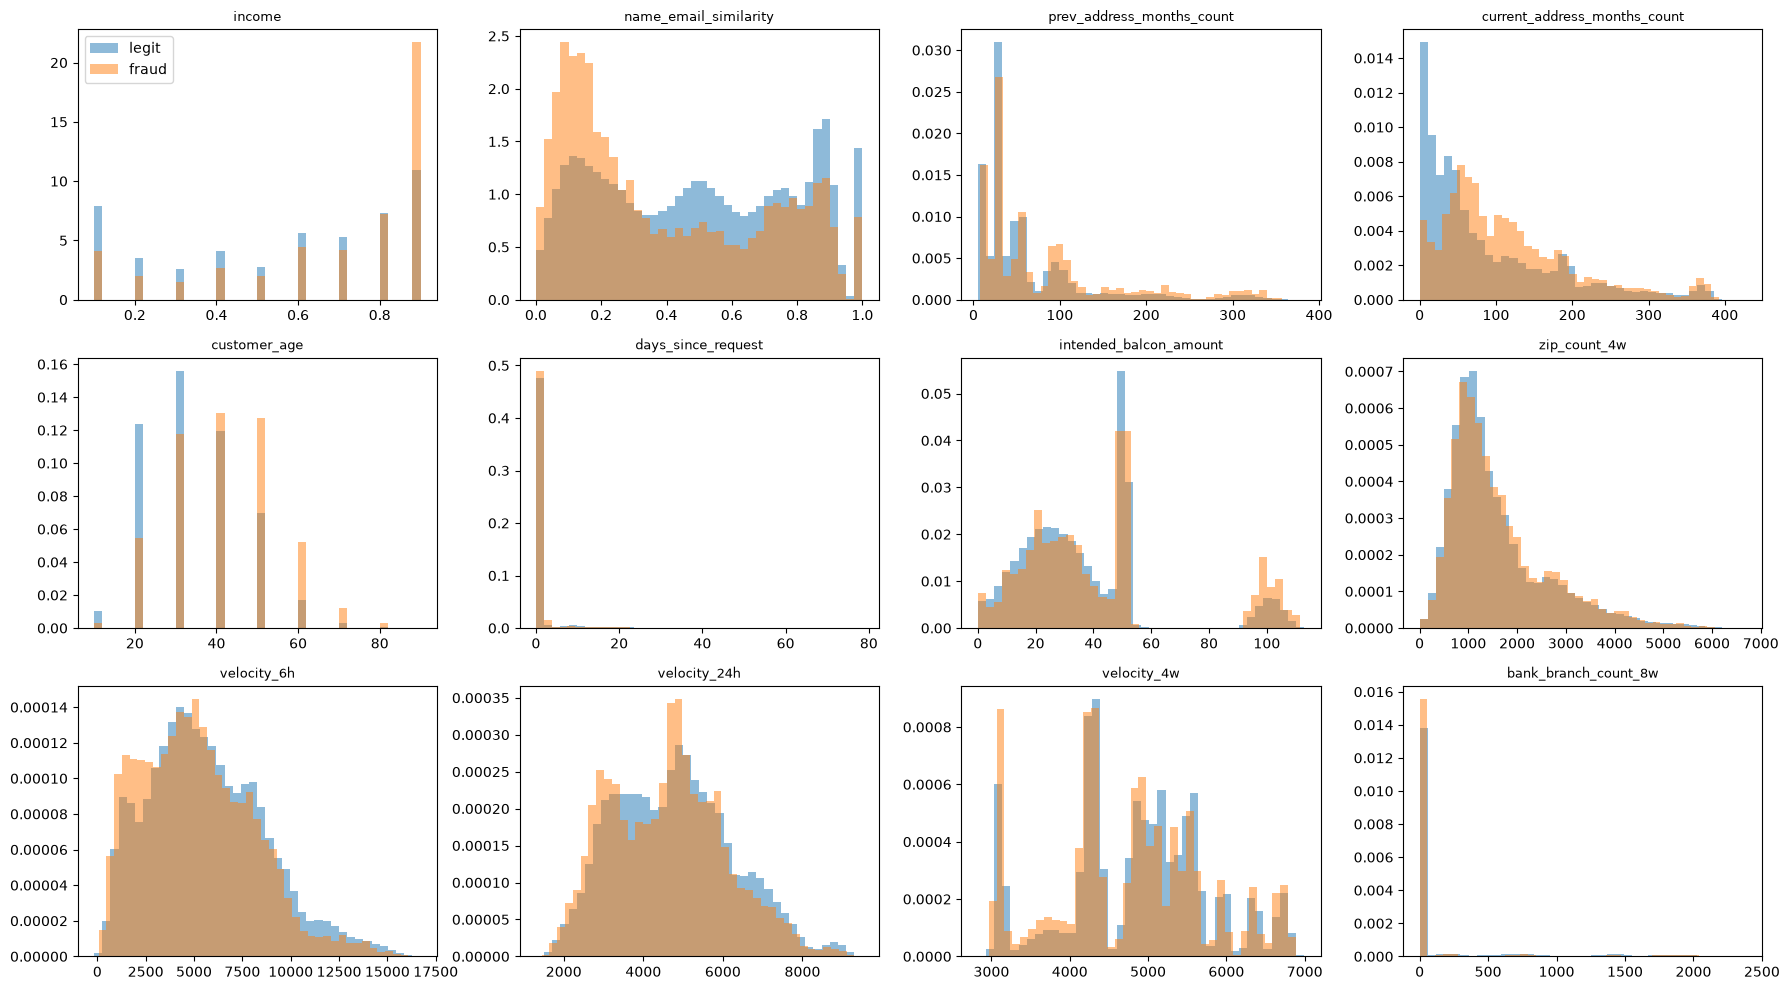

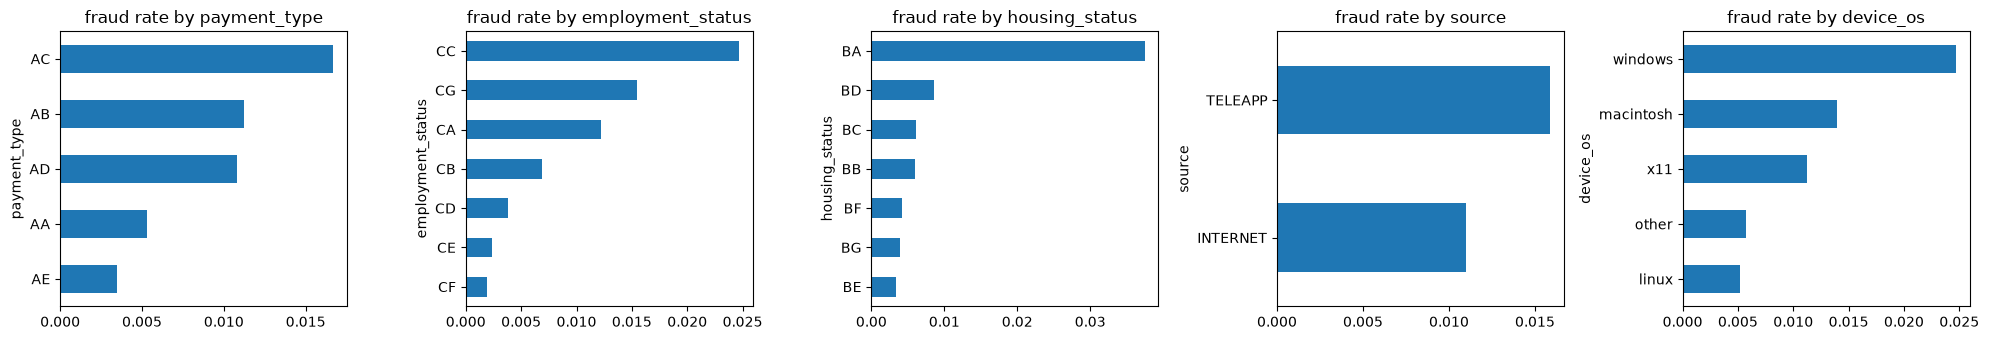

In [7]:
base = datasets["Base"]

# binary columns make unreadable histograms, so only plot ones with more than 2 values
numeric_cols = []
for col in base.columns:
    if col not in CAT_COLS + [TARGET, MONTH, "age_group", "split"] and base[col].nunique() > 2:
        numeric_cols.append(col)

fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.ravel(), numeric_cols[:12]):
    ax.hist(base[base[TARGET] == 0][col].dropna(), bins=40, density=True, alpha=0.5, label="legit")
    ax.hist(base[base[TARGET] == 1][col].dropna(), bins=40, density=True, alpha=0.5, label="fraud")
    ax.set_title(col, fontsize=9)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(CAT_COLS), figsize=(20, 3.5))
for ax, col in zip(axes, CAT_COLS):
    base.groupby(col)[TARGET].mean().sort_values().plot.barh(ax=ax)
    ax.set_title("fraud rate by " + col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 3. Preprocessing and models
* Features: all columns except the label, month and helper columns; columns constant in the **training** months are dropped.
* Numerical: median imputation + missing-indicator columns; standard scaling for logistic regression only.
* Categorical: one-hot encoding (unseen categories ignored).
* All preprocessing is fitted on training months only, inside an sklearn `Pipeline`.
* Class imbalance: class weighting (`balanced` / `scale_pos_weight`); validation and test data keep their natural distribution.

In [8]:
MODEL_NAMES = ["Logistic Regression", "Decision Tree", "Random Forest", "LightGBM", "XGBoost"]


def train_model(train_df, model_name, params):
    features = [c for c in train_df.columns if c not in [TARGET, MONTH, "age_group", "split"]]
    if not INCLUDE_AGE_FEATURE:
        features = [c for c in features if c != AGE]
    # device_fraud_count is constant in training, which would just add a dead column
    features = [c for c in features if train_df[c].nunique(dropna=False) > 1]
    cat_cols = [c for c in features if c in CAT_COLS]
    num_cols = [c for c in features if c not in CAT_COLS]

    y = train_df[TARGET]
    pos_weight = (y == 0).sum() / (y == 1).sum()

    if model_name == "Logistic Regression":
        clf = LogisticRegression(class_weight="balanced", max_iter=2000, **params)
    elif model_name == "Decision Tree":
        clf = DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, **params)
    elif model_name == "Random Forest":
        clf = RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1,
                                     random_state=RANDOM_STATE, **params)
    elif model_name == "LightGBM":
        # multithreaded LightGBM isn't reproducible without deterministic + force_row_wise
        clf = lgb.LGBMClassifier(scale_pos_weight=pos_weight, random_state=RANDOM_STATE, n_jobs=N_THREADS,
                                 deterministic=True, force_row_wise=True, verbose=-1, **params)
    elif model_name == "XGBoost":
        clf = xgb.XGBClassifier(scale_pos_weight=pos_weight, tree_method="hist", eval_metric="aucpr",
                                random_state=RANDOM_STATE, n_jobs=N_THREADS, **params)

    # missingness is itself a fraud signal in BAF, so keep an indicator column after imputing.
    # only logistic regression needs scaling.
    if model_name == "Logistic Regression":
        num_prep = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                             ("scale", StandardScaler())])
    else:
        num_prep = SimpleImputer(strategy="median", add_indicator=True)

    preprocessor = ColumnTransformer([
        ("num", num_prep, num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    pipe.fit(train_df[features], y)
    return pipe, features

## 4. Hyperparameter selection (Base development period only)
Hyperparameters are tuned with Optuna (TPE sampler, seeded) on Base only: each trial trains on months 0–3 and is scored by validation AP on months 4–5. The best setting per model is then **fixed** for all three datasets, so Variants IV and V act as genuine stress tests. The search ranges extend beyond the original small grid, several of whose best values sat at the edge of the grid.

In [9]:
def suggest_params(trial, model_name):
    if model_name == "Logistic Regression":
        return {"C": trial.suggest_float("C", 1e-4, 10, log=True)}
    if model_name == "Decision Tree":
        return {"max_depth": trial.suggest_int("max_depth", 4, 20),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 50, 3000, log=True)}
    if model_name == "Random Forest":
        # trees and row sample are capped so a trial on 550k rows stays around a minute
        return {"n_estimators": 200,
                "max_depth": trial.suggest_categorical("max_depth", [8, 12, 16, 24, None]),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 500, log=True),
                "max_samples": trial.suggest_float("max_samples", 0.1, 0.5)}
    if model_name == "LightGBM":
        return {"n_estimators": trial.suggest_int("n_estimators", 200, 1000, step=100),
                "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
                "num_leaves": trial.suggest_int("num_leaves", 8, 128, log=True),
                "min_child_samples": trial.suggest_int("min_child_samples", 20, 500, log=True),
                "subsample": trial.suggest_float("subsample", 0.5, 1.0),
                "subsample_freq": 1,   # LightGBM ignores subsample unless this is set
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
                "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True)}
    if model_name == "XGBoost":
        return {"n_estimators": trial.suggest_int("n_estimators", 200, 1000, step=100),
                "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
                "max_depth": trial.suggest_int("max_depth", 2, 8),
                "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
                "subsample": trial.suggest_float("subsample", 0.5, 1.0),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
                "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True)}


base_train = datasets["Base"][datasets["Base"]["split"] == "train"]
base_val = datasets["Base"][datasets["Base"]["split"] == "val"]

tuning_rows = []
best_params = {}
for model_name in MODEL_NAMES:
    def objective(trial):
        params = suggest_params(trial, model_name)
        start = time.time()
        pipe, features = train_model(base_train, model_name, params)
        ap = average_precision_score(base_val[TARGET], pipe.predict_proba(base_val[features])[:, 1])
        tuning_rows.append({"model": model_name, "trial": trial.number, "params": json.dumps(params),
                            "val_AP": ap, "secs": time.time() - start})
        # fixed values like subsample_freq aren't in trial.params, so keep the full dict
        trial.set_user_attr("params", params)
        return ap

    # seeded sampler + deterministic models = the same search on every run
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TRIALS[model_name])
    best_params[model_name] = study.best_trial.user_attrs["params"]
    print(model_name, "-> best val AP =", round(study.best_value, 4), best_params[model_name])

tuning = pd.DataFrame(tuning_rows)
tuning.to_csv(OUT_DIR + "/tuning_results.csv", index=False)

Logistic Regression -> best val AP = 0.1446 {'C': 0.00019517224641449495}


Decision Tree -> best val AP = 0.0956 {'max_depth': 14, 'min_samples_leaf': 549}


Random Forest -> best val AP = 0.1456 {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 28, 'max_samples': 0.43149500366077176}


LightGBM -> best val AP = 0.1904 {'n_estimators': 1000, 'learning_rate': 0.02771903532868985, 'num_leaves': 8, 'min_child_samples': 314, 'subsample': 0.6879671402403708, 'subsample_freq': 1, 'colsample_bytree': 0.7710226864052351, 'reg_lambda': 6.128739707832107}


XGBoost -> best val AP = 0.1915 {'n_estimators': 600, 'learning_rate': 0.09123878676869912, 'max_depth': 2, 'min_child_weight': 40.40587768022971, 'subsample': 0.5867547244704671, 'colsample_bytree': 0.9507042305716248, 'reg_lambda': 0.5415930908992359}


## 5. Train on each dataset and score validation + test months
For each dataset, every model is trained on months 0–3 with the fixed hyperparameters and scores months 4–7. The validation scores (months 4–5) set the operating threshold; the test scores (months 6–7) are used only for evaluation.

In [10]:
pred_frames = []
fitted = {}
for dataset, df in datasets.items():
    train = df[df["split"] == "train"]
    eval_df = df[df["split"] != "train"]
    for model_name in MODEL_NAMES:
        pipe, features = train_model(train, model_name, best_params[model_name])
        fitted[(dataset, model_name)] = (pipe, features)
        pred_frames.append(pd.DataFrame({
            "dataset": dataset,
            "model": model_name,
            "row": eval_df.index,
            "month": eval_df[MONTH].values,
            "split": eval_df["split"].values,
            "y": eval_df[TARGET].values,
            "score": pipe.predict_proba(eval_df[features])[:, 1],
            "age_group": eval_df["age_group"].values,
        }))
        print(dataset, "-", model_name, "done")

preds = pd.concat(pred_frames, ignore_index=True)

# the decision tree produces large blocks of identical scores, so a cut-off can land inside a tie
# and flag all or none of it. tiny noise breaks the ties; AP and PR curves still use the raw score.
rng = np.random.default_rng(RANDOM_STATE)
preds["score_tb"] = preds["score"] + rng.uniform(0, 1e-9, len(preds))
preds.head()

Base - Logistic Regression done


Base - Decision Tree done


Base - Random Forest done


Base - LightGBM done


Base - XGBoost done


Variant IV - Logistic Regression done


... (6 outputs left out)

Variant V - Random Forest done


Variant V - LightGBM done


Variant V - XGBoost done


,dataset,model,row,month,split,y,score,age_group,score_tb
0,Base,Logistic Regression,547975,4,val,0,0.1786,<=50,0.1786
1,Base,Logistic Regression,547976,4,val,0,0.7713,<=50,0.7713
2,Base,Logistic Regression,547977,4,val,0,0.0516,<=50,0.0516
3,Base,Logistic Regression,547978,4,val,0,0.8407,<=50,0.8407
4,Base,Logistic Regression,547979,4,val,0,0.0730,<=50,0.0730


## 6. Evaluation helpers
* **AP** depends on fraud prevalence, so a fall in AP can come from a prevalence change alone.
* **Recall at 5% FPR (self-calibrated)** uses the threshold that gives 5% FPR *on the evaluated set itself*. TPR is computed only among frauds and FPR only among legitimate applications, so this metric does not depend on prevalence and measures pure separability.
* **Fixed threshold:** the threshold that gives 5% FPR on validation is applied unchanged; the share of applications flagged can drift.
* **Fixed capacity:** the top *k*% of each month's scores are flagged (no labels needed); the workload is constant and the threshold moves.

In [11]:
def recall_at_fpr(y, scores, fpr=TARGET_FPR):
    # threshold is set on legit applications only, so the result doesn't depend on fraud prevalence
    threshold = np.quantile(scores[y == 0], 1 - fpr)
    return (scores[y == 1] > threshold).mean()


def flag_stats(preds_df, flag_col, group_cols):
    outcomes = preds_df[group_cols].copy()
    outcomes["tp"] = preds_df[flag_col] & (preds_df["y"] == 1)
    outcomes["fp"] = preds_df[flag_col] & (preds_df["y"] == 0)
    outcomes["pos"] = preds_df["y"] == 1
    outcomes["neg"] = preds_df["y"] == 0
    outcomes["flag"] = preds_df[flag_col]
    totals = outcomes.groupby(group_cols).sum()
    counts = outcomes.groupby(group_cols).size()

    stats = pd.DataFrame()
    stats["recall"] = totals["tp"] / totals["pos"]
    stats["FPR"] = totals["fp"] / totals["neg"]
    stats["precision"] = totals["tp"] / totals["flag"]
    stats["alert_rate"] = totals["flag"] / counts
    stats["n"] = counts
    stats["frauds"] = totals["pos"]
    return stats.reset_index()

## 7. Ranking performance: AP vs recall at 5% FPR
If AP falls but recall at 5% FPR is stable, the drop is mostly a prevalence effect. If both fall, the model has genuinely lost its ability to separate fraud from legitimate applications.

In [12]:
def rank_scores(group):
    return pd.Series({
        "prevalence": group["y"].mean(),
        "AP": average_precision_score(group["y"], group["score"]),
        "recall@5%FPR": recall_at_fpr(group["y"].values, group["score_tb"].values),
    })


rank_period = preds.groupby(["dataset", "model", "split"]).apply(rank_scores).reset_index()
rank_month = preds.groupby(["dataset", "model", "month"]).apply(rank_scores).reset_index()

robust = rank_period.pivot_table(index=["dataset", "model"], columns="split",
                                 values=["AP", "recall@5%FPR", "prevalence"])
robust.columns = [metric + "_" + split for metric, split in robust.columns]
robust["AP_change"] = robust["AP_test"] - robust["AP_val"]
robust["recall@5%FPR_change"] = robust["recall@5%FPR_test"] - robust["recall@5%FPR_val"]
robust = robust[["prevalence_val", "prevalence_test", "AP_val", "AP_test", "AP_change",
                 "recall@5%FPR_val", "recall@5%FPR_test", "recall@5%FPR_change"]]
display(robust)

robust.to_csv(OUT_DIR + "/ranking_val_vs_test.csv")
rank_month.to_csv(OUT_DIR + "/ranking_month.csv", index=False)

prevalence_val  prevalence_test  AP_val  \
dataset    model                                                          
Base       Decision Tree                0.0116           0.0140  0.0956   
           LightGBM                     0.0116           0.0140  0.1904   
           Logistic Regression          0.0116           0.0140  0.1446   
           Random Forest                0.0116           0.0140  0.1456   
           XGBoost                      0.0116           0.0140  0.1915   
Variant IV Decision Tree                0.0121           0.0110  0.0997   
           LightGBM                     0.0121           0.0110  0.1961   
           Logistic Regression          0.0121           0.0110  0.1612   
           Random Forest                0.0121           0.0110  0.1600   
           XGBoost                      0.0121           0.0110  0.1966   
Variant V  Decision Tree                0.0121           0.0110  0.3931   
           LightGBM                     0.0121           0.0110  0.5509   
           Logistic Regression          0.0121           0.0110  0.3525   
           Random Forest                0.0121           0.0110  0.5024   
           XGBoost                      0.0121           0.0110  0.5377   

                                AP_test  AP_change  recall@5%FPR_val  \
dataset    model                                                       
Base       Decision Tree         0.1060     0.0104            0.4275   
           LightGBM              0.1963     0.0059            0.5620   
           Logistic Regression   0.1604     0.0158            0.5169   
           Random Forest         0.1645     0.0190            0.5176   
           XGBoost               0.1960     0.0045            0.5606   
Variant IV Decision Tree         0.0577    -0.0419            0.4353   
           LightGBM              0.1173    -0.0787            0.5662   
           Logistic Regression   0.0939    -0.0673            0.5190   
           Random Forest         0.0888    -0.0712            0.5217   
           XGBoost               0.1168    -0.0798            0.5659   
Variant V  Decision Tree         0.0402    -0.3529            0.6315   
           LightGBM              0.0762    -0.4748            0.7662   
           Logistic Regression   0.0693    -0.2831            0.6426   
           Random Forest         0.0715    -0.4309            0.7187   
           XGBoost               0.0838    -0.4539            0.7620   

                                recall@5%FPR_test  recall@5%FPR_change  
dataset    model                                                        
Base       Decision Tree                   0.4124              -0.0151  
           LightGBM                        0.5455              -0.0165  
           Logistic Regression             0.4965              -0.0204  
           Random Forest                   0.5174              -0.0003  
           XGBoost                         0.5434              -0.0172  
Variant IV Decision Tree                   0.3190              -0.1163  
           LightGBM                        0.4472              -0.1190  
           Logistic Regression             0.4046              -0.1144  
           Random Forest                   0.3854              -0.1363  
           XGBoost                         0.4532              -0.1126  
Variant V  Decision Tree                   0.2896              -0.3419  
           LightGBM                        0.3620              -0.4043  
           Logistic Regression             0.3469              -0.2957  
           Random Forest                   0.3612              -0.3575  
           XGBoost                         0.3718              -0.3902

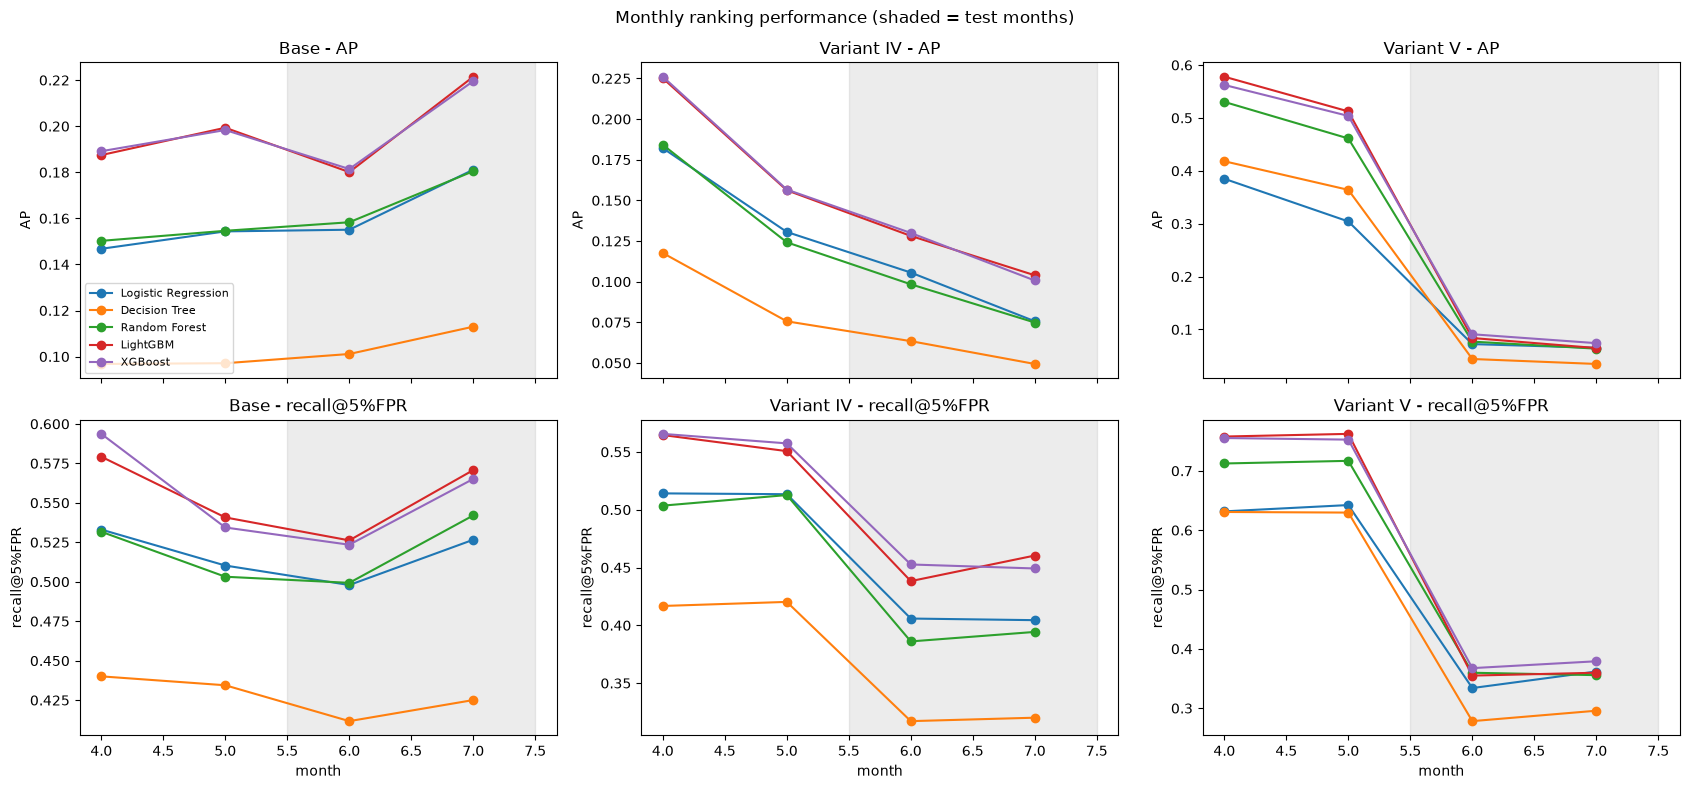

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
for j, dataset in enumerate(datasets):
    for i, metric in enumerate(["AP", "recall@5%FPR"]):
        ax = axes[i, j]
        for model_name in MODEL_NAMES:
            model_month = rank_month[(rank_month["dataset"] == dataset) & (rank_month["model"] == model_name)]
            ax.plot(model_month["month"], model_month[metric], "-o", label=model_name)
        ax.axvspan(TEST_MONTHS[0] - 0.5, TEST_MONTHS[-1] + 0.5, color="grey", alpha=0.15)
        ax.set_title(dataset + " - " + metric)
        ax.set_ylabel(metric)
        if i == 1:
            ax.set_xlabel("month")
axes[0, 0].legend(fontsize=8)
plt.suptitle("Monthly ranking performance (shaded = test months)")
plt.tight_layout()
fig.savefig(OUT_DIR + "/fig2_monthly_ranking.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
# Base has no injected shift, so its change is the baseline drift to subtract
drop_vs_base = robust[["AP_change", "recall@5%FPR_change"]].unstack("dataset")
for variant in ["Variant IV", "Variant V"]:
    for metric in ["AP_change", "recall@5%FPR_change"]:
        drop_vs_base[(metric, variant + " - Base")] = drop_vs_base[(metric, variant)] - drop_vs_base[(metric, "Base")]
drop_vs_base.sort_index(axis=1)

AP_change                                         \
dataset                  Base Variant IV Variant IV - Base Variant V   
model                                                                  
Decision Tree          0.0104    -0.0419           -0.0523   -0.3529   
LightGBM               0.0059    -0.0787           -0.0846   -0.4748   
Logistic Regression    0.0158    -0.0673           -0.0831   -0.2831   
Random Forest          0.0190    -0.0712           -0.0902   -0.4309   
XGBoost                0.0045    -0.0798           -0.0843   -0.4539   

                                     recall@5%FPR_change             \
dataset             Variant V - Base                Base Variant IV   
model                                                                 
Decision Tree                -0.3633             -0.0151    -0.1163   
LightGBM                     -0.4807             -0.0165    -0.1190   
Logistic Regression          -0.2989             -0.0204    -0.1144   
Random Forest                -0.4499             -0.0003    -0.1363   
XGBoost                      -0.4584             -0.0172    -0.1126   

                                                                  
dataset             Variant IV - Base Variant V Variant V - Base  
model                                                             
Decision Tree                 -0.1012   -0.3419          -0.3268  
LightGBM                      -0.1025   -0.4043          -0.3878  
Logistic Regression           -0.0939   -0.2957          -0.2753  
Random Forest                 -0.1360   -0.3575          -0.3572  
XGBoost                       -0.0955   -0.3902          -0.3731

### 7.1 Two definitions of robustness (RQ1)
* **Out-of-time performance:** test recall at 5% FPR — what the bank actually gets.
* **Stability:** the change from validation to test, net of the same model's change on Base (`shift_effect`), so normal month-to-month drift is removed and only the injected shift remains. `retention` = test / validation recall.

A model can rank high on one and low on the other (e.g. a weak model has little to lose).

In [15]:
robustness = robust[["recall@5%FPR_val", "recall@5%FPR_test", "recall@5%FPR_change"]].reset_index()

base_change = robustness[robustness["dataset"] == "Base"].set_index("model")["recall@5%FPR_change"]
robustness["shift_effect"] = robustness["recall@5%FPR_change"] - robustness["model"].map(base_change)
robustness["retention"] = robustness["recall@5%FPR_test"] / robustness["recall@5%FPR_val"]

robustness["rank_performance"] = robustness.groupby("dataset")["recall@5%FPR_test"].rank(ascending=False)
# shift_effect is 0 by construction on Base, so rank Base on its raw change instead
robustness["stability"] = np.where(robustness["dataset"] == "Base",
                                   robustness["recall@5%FPR_change"], robustness["shift_effect"])
robustness["rank_stability"] = robustness.groupby("dataset")["stability"].rank(ascending=False)
robustness = robustness.drop(columns="stability")

display(robustness.round(3))
robustness.to_csv(OUT_DIR + "/robustness.csv", index=False)

,dataset,model,recall@5%FPR_val,recall@5%FPR_test,recall@5%FPR_change,shift_effect,retention,rank_performance,rank_stability
0,Base,Decision Tree,0.4280,0.4120,-0.0150,0.0000,0.9650,5.0000,2.0000
1,Base,LightGBM,0.5620,0.5460,-0.0160,0.0000,0.9710,1.0000,3.0000
2,Base,Logistic Regression,0.5170,0.4970,-0.0200,0.0000,0.9610,4.0000,5.0000
3,Base,Random Forest,0.5180,0.5170,-0.0000,0.0000,0.9990,3.0000,1.0000
4,Base,XGBoost,0.5610,0.5430,-0.0170,0.0000,0.9690,2.0000,4.0000
5,Variant IV,Decision Tree,0.4350,0.3190,-0.1160,-0.1010,0.7330,5.0000,3.0000
6,Variant IV,LightGBM,0.5660,0.4470,-0.1190,-0.1020,0.7900,2.0000,4.0000
7,Variant IV,Logistic Regression,0.5190,0.4050,-0.1140,-0.0940,0.7800,3.0000,1.0000
8,Variant IV,Random Forest,0.5220,0.3850,-0.1360,-0.1360,0.7390,4.0000,5.0000
9,Variant IV,XGBoost,0.5660,0.4530,-0.1130,-0.0950,0.8010,1.0000,2.0000


### 7.2 Precision–recall curves and best model
The "best" model for the detailed plots below is the one with the highest **Base validation AP**, so it is chosen without looking at test data.

Best model on Base validation AP: XGBoost


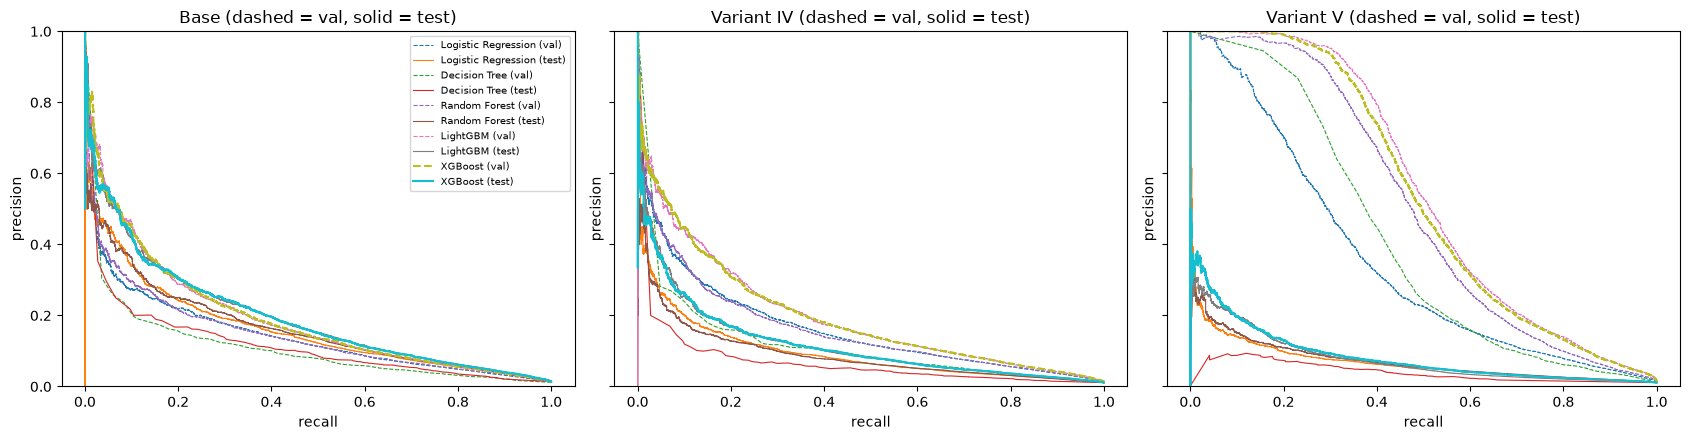

In [16]:
# pick the model on Base validation only, so the test months stay untouched
base_val_rank = rank_period[(rank_period["dataset"] == "Base") & (rank_period["split"] == "val")]
BEST = base_val_rank.sort_values("AP", ascending=False)["model"].iloc[0]
print("Best model on Base validation AP:", BEST)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, dataset in zip(axes, datasets):
    for model_name in MODEL_NAMES:
        for split, style in [("val", "--"), ("test", "-")]:
            split_preds = preds[(preds["dataset"] == dataset) & (preds["model"] == model_name) & (preds["split"] == split)]
            precision, recall, _ = precision_recall_curve(split_preds["y"], split_preds["score"])
            width = 1.5 if model_name == BEST else 0.8
            label = model_name + " (" + split + ")" if dataset == "Base" else None
            ax.plot(recall, precision, style, lw=width, label=label)
    ax.set_title(dataset + " (dashed = val, solid = test)")
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.set_ylim(0, 1)
axes[0].legend(fontsize=7)
plt.tight_layout()
fig.savefig(OUT_DIR + "/fig5_pr_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Operating setting A — fixed threshold (primary)
The threshold giving 5% FPR on the validation months is applied unchanged to each test month. Because the threshold is fixed, the alert rate (share of applications sent for review) can drift.

In [17]:
val_preds = preds[preds["split"] == "val"]
threshold_rows = []
for (dataset, model_name), model_val in val_preds.groupby(["dataset", "model"]):
    threshold = np.quantile(model_val[model_val["y"] == 0]["score_tb"], 1 - TARGET_FPR)
    threshold_rows.append({"dataset": dataset, "model": model_name, "thr": threshold})
thresholds = pd.DataFrame(threshold_rows)

# drop first so re-running the cell doesn't produce thr_x / thr_y
preds = preds.drop(columns="thr", errors="ignore")
preds = preds.merge(thresholds, on=["dataset", "model"])
preds["flag_thr"] = preds["score_tb"] > preds["thr"]

thr_period = flag_stats(preds, "flag_thr", ["dataset", "model", "split"])
thr_month = flag_stats(preds, "flag_thr", ["dataset", "model", "month"])
display(thr_period.pivot_table(index=["dataset", "model"], columns="split",
                               values=["recall", "FPR", "precision", "alert_rate"]))
thr_period.to_csv(OUT_DIR + "/fixed_threshold_period.csv", index=False)
thr_month.to_csv(OUT_DIR + "/fixed_threshold_month.csv", index=False)

FPR        alert_rate        precision  \
split                            test    val       test    val      test   
dataset    model                                                           
Base       Decision Tree       0.0433 0.0500     0.0481 0.0544    0.1124   
           LightGBM            0.0414 0.0500     0.0479 0.0559    0.1490   
           Logistic Regression 0.0322 0.0500     0.0375 0.0554    0.1518   
           Random Forest       0.0358 0.0500     0.0415 0.0554    0.1492   
           XGBoost             0.0441 0.0500     0.0507 0.0559    0.1427   
Variant IV Decision Tree       0.0484 0.0500     0.0512 0.0547    0.0653   
           LightGBM            0.0496 0.0500     0.0540 0.0563    0.0906   
           Logistic Regression 0.0391 0.0500     0.0425 0.0557    0.0909   
           Random Forest       0.0416 0.0500     0.0450 0.0557    0.0858   
           XGBoost             0.0528 0.0500     0.0573 0.0563    0.0883   
Variant V  Decision Tree       0.0487 0.0500     0.0512 0.0571    0.0604   
           LightGBM            0.0442 0.0500     0.0474 0.0587    0.0779   
           Logistic Regression 0.0384 0.0500     0.0412 0.0572    0.0769   
           Random Forest       0.0427 0.0500     0.0459 0.0581    0.0790   
           XGBoost             0.0459 0.0500     0.0493 0.0586    0.0796   

                                      recall         
split                             val   test    val  
dataset    model                                     
Base       Decision Tree       0.0911 0.3853 0.4275  
           LightGBM            0.1165 0.5087 0.5620  
           Logistic Regression 0.1081 0.4051 0.5169  
           Random Forest       0.1083 0.4413 0.5176  
           XGBoost             0.1162 0.5153 0.5606  
Variant IV Decision Tree       0.0966 0.3047 0.4353  
           LightGBM            0.1221 0.4453 0.5662  
           Logistic Regression 0.1131 0.3522 0.5190  
           Random Forest       0.1136 0.3518 0.5217  
           XGBoost             0.1221 0.4615 0.5659  
Variant V  Decision Tree       0.1343 0.2821 0.6315  
           LightGBM            0.1585 0.3360 0.7662  
           Logistic Regression 0.1364 0.2885 0.6426  
           Random Forest       0.1501 0.3299 0.7187  
           XGBoost             0.1577 0.3575 0.7620

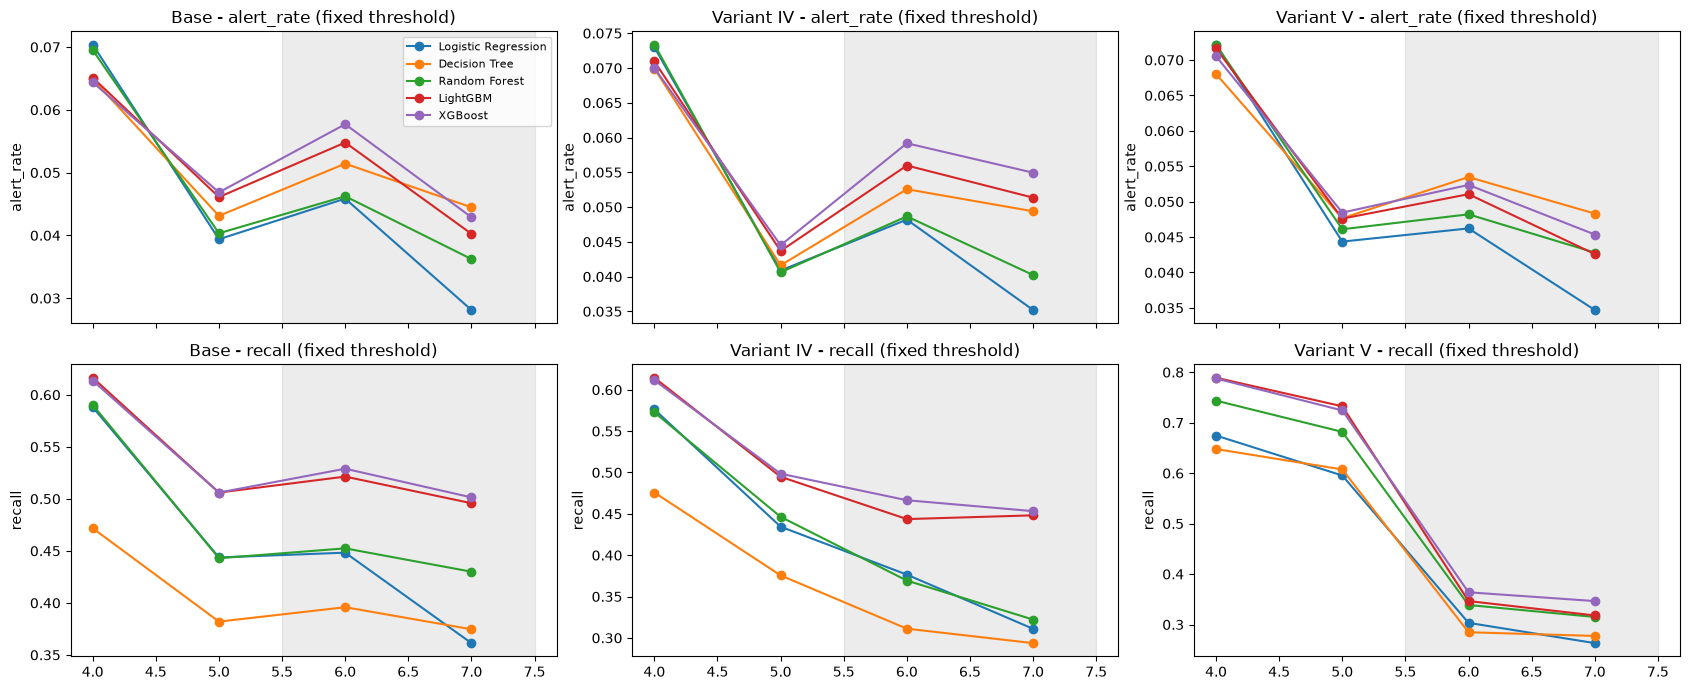

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 7), sharex=True)
for j, dataset in enumerate(datasets):
    for i, metric in enumerate(["alert_rate", "recall"]):
        ax = axes[i, j]
        for model_name in MODEL_NAMES:
            model_month = thr_month[(thr_month["dataset"] == dataset) & (thr_month["model"] == model_name)]
            ax.plot(model_month["month"], model_month[metric], "-o", label=model_name)
        ax.axvspan(TEST_MONTHS[0] - 0.5, TEST_MONTHS[-1] + 0.5, color="grey", alpha=0.15)
        ax.set_title(dataset + " - " + metric + " (fixed threshold)")
        ax.set_ylabel(metric)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

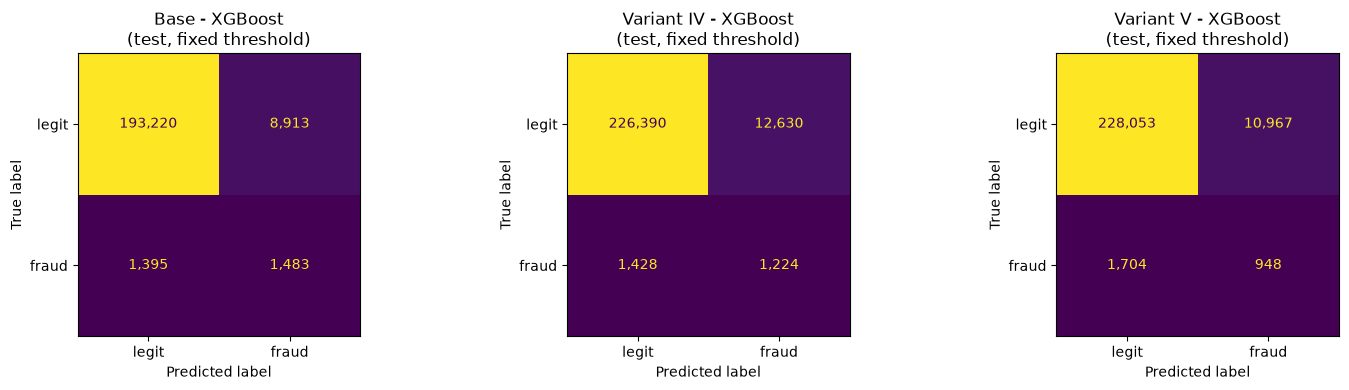

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, dataset in zip(axes, datasets):
    test_preds = preds[(preds["dataset"] == dataset) & (preds["model"] == BEST) & (preds["split"] == "test")]
    cm = confusion_matrix(test_preds["y"], test_preds["flag_thr"])
    ConfusionMatrixDisplay(cm, display_labels=["legit", "fraud"]).plot(ax=ax, colorbar=False, values_format=",")
    ax.set_title(dataset + " - " + BEST + "\n(test, fixed threshold)")
plt.tight_layout()
fig.savefig(OUT_DIR + "/fig6_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Operating setting B — fixed review capacity (secondary)
Each month, the highest-scoring 1% and 5% of applications are sent for review. Workload is constant and the threshold changes month to month. Only that month's scores are used (no labels), so there is no leakage.

In [20]:
# rank within each month so the review workload stays fixed even if the scores drift
month_scores = preds.groupby(["dataset", "model", "month"])["score_tb"]
month_size = month_scores.transform("size")
rank_in_month = month_scores.rank(method="first", ascending=False)

cap_tables = []
for cap in REVIEW_CAPACITIES:
    col = "flag_cap" + str(int(cap * 100))
    preds[col] = rank_in_month <= np.ceil(cap * month_size)
    cap_stats = flag_stats(preds, col, ["dataset", "model", "split"])
    cap_stats["capacity"] = cap
    cap_tables.append(cap_stats)
cap_period = pd.concat(cap_tables, ignore_index=True)

display(cap_period.pivot_table(index=["dataset", "model"], columns=["capacity", "split"], values=["recall", "FPR"]))
cap_period.to_csv(OUT_DIR + "/fixed_capacity_period.csv", index=False)

FPR                      recall         \
capacity                       0.0100        0.0500        0.0100          
split                            test    val   test    val   test    val   
dataset    model                                                           
Base       Decision Tree       0.0081 0.0083 0.0452 0.0457 0.1411 0.1519   
           LightGBM            0.0071 0.0073 0.0433 0.0443 0.2133 0.2368   
           Logistic Regression 0.0075 0.0078 0.0439 0.0448 0.1894 0.2015   
           Random Forest       0.0075 0.0077 0.0437 0.0448 0.1838 0.2061   
           XGBoost             0.0071 0.0073 0.0434 0.0443 0.2140 0.2379   
Variant IV Decision Tree       0.0089 0.0084 0.0472 0.0458 0.1071 0.1435   
           LightGBM            0.0082 0.0073 0.0458 0.0441 0.1719 0.2280   
           Logistic Regression 0.0085 0.0077 0.0463 0.0447 0.1486 0.1974   
           Random Forest       0.0086 0.0079 0.0464 0.0448 0.1391 0.1841   
           XGBoost             0.0082 0.0074 0.0457 0.0441 0.1708 0.2235   
Variant V  Decision Tree       0.0092 0.0054 0.0475 0.0432 0.0814 0.3839   
           LightGBM            0.0085 0.0043 0.0467 0.0417 0.1456 0.4705   
           Logistic Regression 0.0088 0.0060 0.0469 0.0431 0.1176 0.3348   
           Random Forest       0.0087 0.0047 0.0467 0.0422 0.1233 0.4389   
           XGBoost             0.0085 0.0045 0.0466 0.0417 0.1474 0.4588   

                                              
capacity                       0.0500         
split                            test    val  
dataset    model                              
Base       Decision Tree       0.3909 0.4143  
           LightGBM            0.5240 0.5389  
           Logistic Regression 0.4823 0.4963  
           Random Forest       0.4917 0.4932  
           XGBoost             0.5156 0.5365  
Variant IV Decision Tree       0.3017 0.3959  
           LightGBM            0.4299 0.5280  
           Logistic Regression 0.3876 0.4841  
           Random Forest       0.3733 0.4762  
           XGBoost             0.4355 0.5322  
Variant V  Decision Tree       0.2771 0.6050  
           LightGBM            0.3443 0.7277  
           Logistic Regression 0.3299 0.6080  
           Random Forest       0.3458 0.6865  
           XGBoost             0.3594 0.7226

### 9.1 Fixed threshold vs fixed capacity at the same workload
The 1% / 5% capacities flag a different share of applications than the fixed threshold does, so their recalls are not directly comparable. Here each model's capacity is set to the share of **validation** applications its fixed threshold flagged, so both settings start from the same workload; any test-period difference comes from the threshold going stale vs moving with the scores.


In [21]:
val_alert = thr_period[thr_period["split"] == "val"][["dataset", "model", "alert_rate"]]
matched_cap = preds[["dataset", "model"]].merge(val_alert, on=["dataset", "model"], how="left")["alert_rate"].values
preds["flag_cap_matched"] = rank_in_month.values <= np.ceil(matched_cap * month_size.values)

matched = pd.concat([
    flag_stats(preds, "flag_thr", ["dataset", "model", "split"]).assign(setting="fixed threshold"),
    flag_stats(preds, "flag_cap_matched", ["dataset", "model", "split"]).assign(setting="matched capacity"),
], ignore_index=True)
display(matched[matched["split"] == "test"].pivot_table(index=["dataset", "model"], columns="setting",
                                                         values=["alert_rate", "recall", "FPR"]).round(3))
matched.to_csv(OUT_DIR + "/threshold_vs_matched_capacity.csv", index=False)


FPR                   \
setting                        fixed threshold matched capacity   
dataset    model                                                  
Base       Decision Tree                0.0430           0.0490   
           LightGBM                     0.0410           0.0490   
           Logistic Regression          0.0320           0.0490   
           Random Forest                0.0360           0.0490   
           XGBoost                      0.0440           0.0490   
Variant IV Decision Tree                0.0480           0.0520   
           LightGBM                     0.0500           0.0520   
           Logistic Regression          0.0390           0.0520   
           Random Forest                0.0420           0.0520   
           XGBoost                      0.0530           0.0520   
Variant V  Decision Tree                0.0490           0.0540   
           LightGBM                     0.0440           0.0550   
           Logistic Regression          0.0380           0.0540   
           Random Forest                0.0430           0.0550   
           XGBoost                      0.0460           0.0550   

                                    alert_rate                   \
setting                        fixed threshold matched capacity   
dataset    model                                                  
Base       Decision Tree                0.0480           0.0540   
           LightGBM                     0.0480           0.0560   
           Logistic Regression          0.0370           0.0550   
           Random Forest                0.0420           0.0550   
           XGBoost                      0.0510           0.0560   
Variant IV Decision Tree                0.0510           0.0550   
           LightGBM                     0.0540           0.0560   
           Logistic Regression          0.0430           0.0560   
           Random Forest                0.0450           0.0560   
           XGBoost                      0.0570           0.0560   
Variant V  Decision Tree                0.0510           0.0570   
           LightGBM                     0.0470           0.0590   
           Logistic Regression          0.0410           0.0570   
           Random Forest                0.0460           0.0580   
           XGBoost                      0.0490           0.0590   

                                        recall                   
setting                        fixed threshold matched capacity  
dataset    model                                                 
Base       Decision Tree                0.3850           0.4120  
           LightGBM                     0.5090           0.5440  
           Logistic Regression          0.4050           0.5060  
           Random Forest                0.4410           0.5150  
           XGBoost                      0.5150           0.5400  
Variant IV Decision Tree                0.3050           0.3250  
           LightGBM                     0.4450           0.4540  
           Logistic Regression          0.3520           0.4110  
           Random Forest                0.3520           0.3970  
           XGBoost                      0.4620           0.4580  
Variant V  Decision Tree                0.2820           0.3030  
           LightGBM                     0.3360           0.3740  
           Logistic Regression          0.2880           0.3580  
           Random Forest                0.3300           0.3750  
           XGBoost                      0.3570           0.3880

## 10. Age-group comparison (≤50 vs >50)
**Primary analysis: fixed threshold.** This isolates how each model's scores behave for each group. The fixed-capacity results are a secondary check: under fixed capacity, if one group's scores rise, that group takes up more review slots, and both groups' rates shift as a result.

`FPR_ratio_>50/<=50` > 1 means older applicants are wrongly flagged more often.

In [22]:
age_gaps = {}
for flag_col in ["flag_thr"] + ["flag_cap" + str(int(cap * 100)) for cap in REVIEW_CAPACITIES]:
    age_stats = flag_stats(preds, flag_col, ["dataset", "model", "split", "age_group"])
    if flag_col == "flag_thr":
        age_thr = age_stats

    gap = age_stats.pivot_table(index=["dataset", "model", "split"], columns="age_group", values=["FPR", "recall"])
    gap.columns = [metric + "_" + group for metric, group in gap.columns]
    gap["FPR_ratio_>50/<=50"] = gap["FPR_>50"] / gap["FPR_<=50"]
    gap["recall_diff_>50-<=50"] = gap["recall_>50"] - gap["recall_<=50"]
    age_gaps[flag_col] = gap

gap_thr = age_gaps["flag_thr"]
print("PRIMARY - fixed threshold (5% FPR on validation)")
display(gap_thr)
for cap in REVIEW_CAPACITIES:
    print("\nSECONDARY - fixed capacity", cap)
    display(age_gaps["flag_cap" + str(int(cap * 100))])

gap_thr.to_csv(OUT_DIR + "/age_gap_fixed_threshold.csv")
gap_cap = {cap: age_gaps["flag_cap" + str(int(cap * 100))] for cap in REVIEW_CAPACITIES}
pd.concat(gap_cap, names=["capacity"]).to_csv(OUT_DIR + "/age_gap_fixed_capacity.csv")

PRIMARY - fixed threshold (5% FPR on validation)


FPR_<=50  FPR_>50  recall_<=50  \
dataset    model               split                                   
Base       Decision Tree       test     0.0413   0.0940       0.3736   
                               val      0.0473   0.1113       0.4199   
           LightGBM            test     0.0376   0.1352       0.4803   
                               val      0.0450   0.1640       0.5309   
           Logistic Regression test     0.0293   0.1073       0.3716   
                               val      0.0454   0.1552       0.4869   
           Random Forest       test     0.0333   0.0997       0.4200   
                               val      0.0462   0.1364       0.4970   
           XGBoost             test     0.0403   0.1386       0.4859   
                               val      0.0449   0.1650       0.5296   
Variant IV Decision Tree       test     0.0417   0.0949       0.2658   
                               val      0.0431   0.0989       0.4127   
           LightGBM            test     0.0404   0.1137       0.4049   
                               val      0.0398   0.1220       0.5188   
           Logistic Regression test     0.0301   0.1014       0.3026   
                               val      0.0387   0.1301       0.4615   
           Random Forest       test     0.0350   0.0871       0.3128   
                               val      0.0421   0.1058       0.4897   
           XGBoost             test     0.0428   0.1228       0.4173   
                               val      0.0398   0.1223       0.5167   
Variant V  Decision Tree       test     0.0463   0.0649       0.2621   
                               val      0.0481   0.0636       0.6837   
           LightGBM            test     0.0354   0.1053       0.2653   
                               val      0.0403   0.1177       0.7856   
           Logistic Regression test     0.0314   0.0880       0.2449   
                               val      0.0411   0.1121       0.6746   
           Random Forest       test     0.0394   0.0656       0.2945   
                               val      0.0457   0.0804       0.7637   
           XGBoost             test     0.0367   0.1102       0.2899   
                               val      0.0398   0.1213       0.7801   

                                      recall_>50  FPR_ratio_>50/<=50  \
dataset    model               split                                   
Base       Decision Tree       test       0.4680              2.2749   
                               val        0.4766              2.3529   
           LightGBM            test       0.7075              3.5933   
                               val        0.7630              3.6458   
           Logistic Regression test       0.6407              3.6686   
                               val        0.7109              3.4199   
           Random Forest       test       0.5905              2.9961   
                               val        0.6510              2.9534   
           XGBoost             test       0.7214              3.4355   
                               val        0.7604              3.6734   
Variant IV Decision Tree       test       0.4802              2.2764   
                               val        0.4888              2.2948   
           LightGBM            test       0.6279              2.8134   
                               val        0.6785              3.0650   
           Logistic Regression test       0.5759              3.3648   
                               val        0.6552              3.3647   
           Random Forest       test       0.5281              2.4860   
                               val        0.5974              2.5106   
           XGBoost             test       0.6611              2.8673   
                               val        0.6826              3.0747   
Variant V  Decision Tree       test       0.3690              1.4009   
                               val        0.3830              1.3232   
     


SECONDARY - fixed capacity 0.01


FPR_<=50  FPR_>50  recall_<=50  \
dataset    model               split                                   
Base       Decision Tree       test     0.0077   0.0198       0.1338   
                               val      0.0078   0.0195       0.1452   
           LightGBM            test     0.0061   0.0319       0.1909   
                               val      0.0062   0.0343       0.2158   
           Logistic Regression test     0.0065   0.0303       0.1691   
                               val      0.0065   0.0354       0.1815   
           Random Forest       test     0.0069   0.0229       0.1707   
                               val      0.0070   0.0238       0.1948   
           XGBoost             test     0.0061   0.0322       0.1902   
                               val      0.0061   0.0358       0.2142   
Variant IV Decision Tree       test     0.0074   0.0197       0.0843   
                               val      0.0068   0.0193       0.1219   
           LightGBM            test     0.0061   0.0228       0.1442   
                               val      0.0054   0.0209       0.1929   
           Logistic Regression test     0.0056   0.0283       0.1133   
                               val      0.0052   0.0257       0.1527   
           Random Forest       test     0.0070   0.0194       0.1147   
                               val      0.0065   0.0172       0.1664   
           XGBoost             test     0.0061   0.0231       0.1451   
                               val      0.0055   0.0209       0.1895   
Variant V  Decision Tree       test     0.0096   0.0062       0.0728   
                               val      0.0060   0.0015       0.4565   
           LightGBM            test     0.0068   0.0204       0.1067   
                               val      0.0036   0.0094       0.5326   
           Logistic Regression test     0.0067   0.0239       0.0951   
                               val      0.0045   0.0166       0.3691   
           Random Forest       test     0.0080   0.0137       0.1062   
                               val      0.0045   0.0061       0.5038   
           XGBoost             test     0.0066   0.0217       0.1081   
                               val      0.0035   0.0116       0.5166   

                                      recall_>50  FPR_ratio_>50/<=50  \
dataset    model               split                                   
Base       Decision Tree       test       0.1922              2.5741   
                               val        0.1953              2.4854   
           LightGBM            test       0.3705              5.2102   
                               val        0.3724              5.5819   
           Logistic Regression test       0.3315              4.6412   
                               val        0.3307              5.4166   
           Random Forest       test       0.2758              3.3034   
                               val        0.2786              3.3980   
           XGBoost             test       0.3816              5.2701   
                               val        0.3906              5.8921   
Variant IV Decision Tree       test       0.2100              2.6779   
                               val        0.1947              2.8335   
           LightGBM            test       0.2973              3.7422   
                               val        0.3114              3.8649   
           Logistic Regression test       0.3077              5.0513   
                               val        0.3032              4.9833   
           Random Forest       test       0.2495              2.7674   
                               val        0.2262              2.6204   
           XGBoost             test       0.2869              3.8092   
                               val        0.3043              3.8202   
Variant V  Decision Tree       test       0.1190              0.6479   
                               val        0.0381              0.2579   
     


SECONDARY - fixed capacity 0.05


FPR_<=50  FPR_>50  recall_<=50  \
dataset    model               split                                   
Base       Decision Tree       test     0.0431   0.0956       0.3795   
                               val      0.0437   0.0915       0.4090   
           LightGBM            test     0.0395   0.1374       0.4982   
                               val      0.0397   0.1472       0.5083   
           Logistic Regression test     0.0404   0.1316       0.4506   
                               val      0.0406   0.1398       0.4699   
           Random Forest       test     0.0408   0.1167       0.4708   
                               val      0.0413   0.1236       0.4740   
           XGBoost             test     0.0398   0.1334       0.4875   
                               val      0.0396   0.1507       0.5075   
Variant IV Decision Tree       test     0.0408   0.0917       0.2649   
                               val      0.0393   0.0916       0.3683   
           LightGBM            test     0.0371   0.1062       0.3906   
                               val      0.0350   0.1088       0.4790   
           Logistic Regression test     0.0360   0.1179       0.3358   
                               val      0.0343   0.1182       0.4213   
           Random Forest       test     0.0392   0.0968       0.3344   
                               val      0.0376   0.0953       0.4444   
           XGBoost             test     0.0368   0.1080       0.3938   
                               val      0.0347   0.1102       0.4773   
Variant V  Decision Tree       test     0.0452   0.0638       0.2574   
                               val      0.0419   0.0521       0.6614   
           LightGBM            test     0.0375   0.1117       0.2723   
                               val      0.0335   0.0987       0.7539   
           Logistic Regression test     0.0386   0.1052       0.2829   
                               val      0.0353   0.0982       0.6403   
           Random Forest       test     0.0432   0.0711       0.3103   
                               val      0.0386   0.0670       0.7332   
           XGBoost             test     0.0373   0.1115       0.2913   
                               val      0.0330   0.1026       0.7470   

                                      recall_>50  FPR_ratio_>50/<=50  \
dataset    model               split                                   
Base       Decision Tree       test       0.4708              2.2148   
                               val        0.4479              2.0930   
           LightGBM            test       0.7047              3.4777   
                               val        0.7370              3.7044   
           Logistic Regression test       0.7047              3.2605   
                               val        0.6667              3.4454   
           Random Forest       test       0.6379              2.8605   
                               val        0.6172              2.9906   
           XGBoost             test       0.7131              3.3523   
                               val        0.7240              3.8042   
Variant IV Decision Tree       test       0.4678              2.2473   
                               val        0.4615              2.3338   
           LightGBM            test       0.6071              2.8627   
                               val        0.6440              3.1107   
           Logistic Regression test       0.6216              3.2750   
                               val        0.6329              3.4497   
           Random Forest       test       0.5489              2.4717   
                               val        0.5517              2.5345   
           XGBoost             test       0.6237              2.9374   
                               val        0.6623              3.1729   
Variant V  Decision Tree       test       0.3629              1.4132   
                               val        0.3362              1.2429   
     

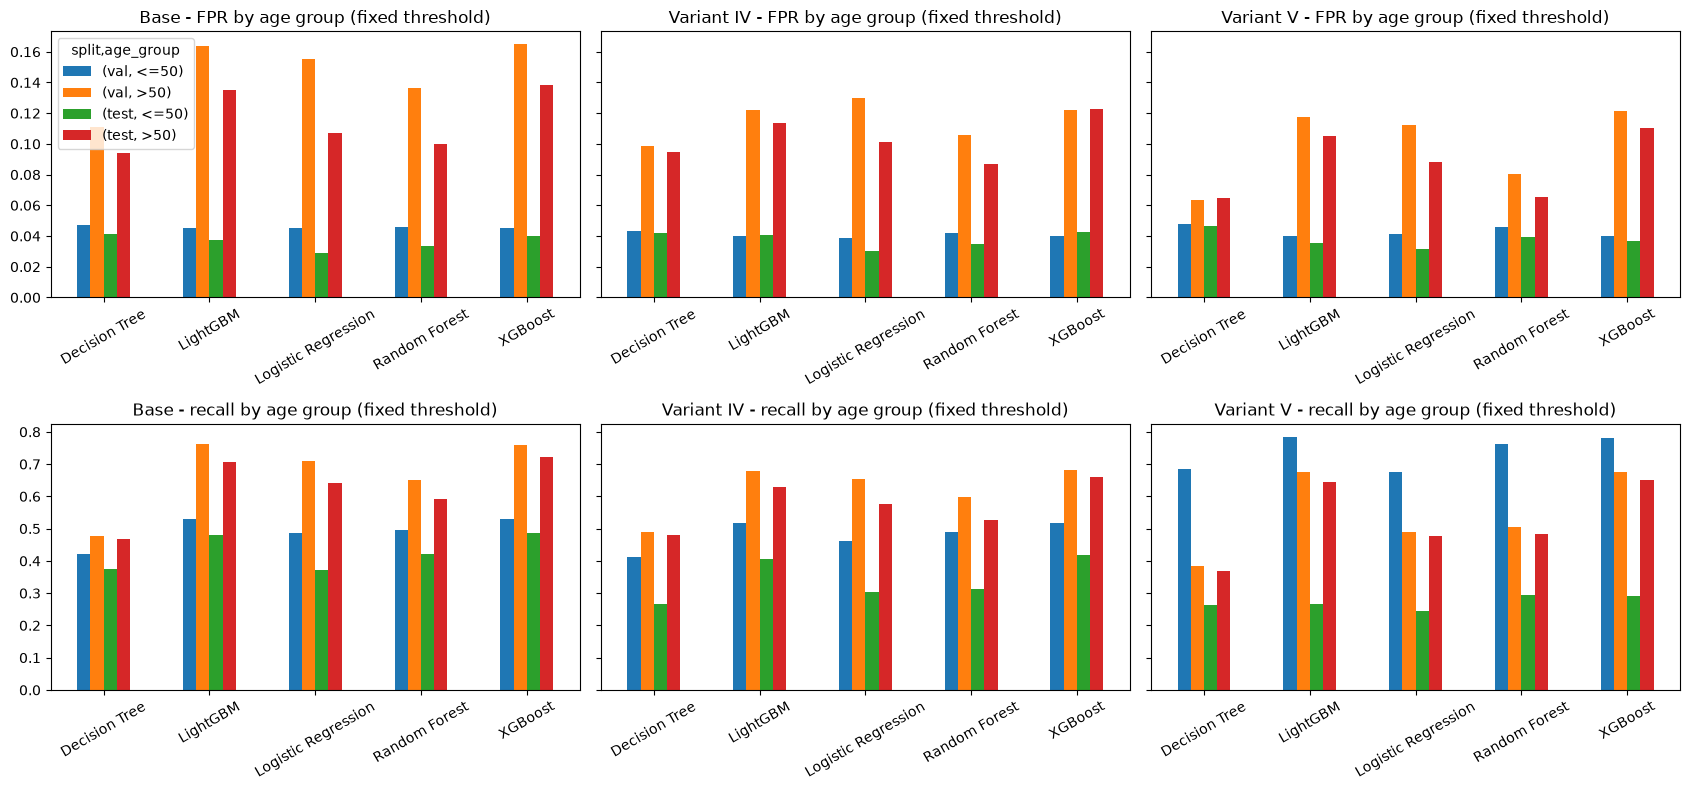

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharey="row")
for j, dataset in enumerate(datasets):
    for i, metric in enumerate(["FPR", "recall"]):
        ax = axes[i, j]
        by_age = age_thr[age_thr["dataset"] == dataset].pivot_table(index="model", columns=["split", "age_group"],
                                                                     values=metric)
        by_age = by_age[[("val", "<=50"), ("val", ">50"), ("test", "<=50"), ("test", ">50")]]
        by_age.plot.bar(ax=ax, rot=30, legend=(i == 0 and j == 0))
        ax.set_title(dataset + " - " + metric + " by age group (fixed threshold)")
        ax.set_xlabel("")
plt.tight_layout()
fig.savefig(OUT_DIR + "/fig3_age_groups.png", dpi=200, bbox_inches="tight")
plt.show()

### 10.1 Separability within each age group
Recall at 5% FPR recomputed **within each age group and period**, so it does not depend on the validation threshold. If a group's fixed-threshold recall falls but this stays steady, the threshold has gone stale for that group; if both fall, the model ranks that group's frauds worse.

In [24]:
rank_age = preds.groupby(["dataset", "model", "split", "age_group"]).apply(rank_scores).reset_index()
display(rank_age.pivot_table(index=["dataset", "model"], columns=["age_group", "split"], values="recall@5%FPR").round(3))
rank_age.to_csv(OUT_DIR + "/ranking_by_age.csv", index=False)

age_group                        <=50           >50       
split                            test    val   test    val
dataset    model                                          
Base       Decision Tree       0.4120 0.4300 0.3340 0.3180
           LightGBM            0.5390 0.5480 0.4790 0.4510
           Logistic Regression 0.4800 0.5100 0.4260 0.4010
           Random Forest       0.5070 0.5110 0.4230 0.4060
           XGBoost             0.5350 0.5490 0.4790 0.4560
Variant IV Decision Tree       0.3000 0.4460 0.3450 0.3400
           LightGBM            0.4540 0.5730 0.4240 0.4770
           Logistic Regression 0.4000 0.5170 0.4160 0.4290
           Random Forest       0.3850 0.5240 0.4070 0.4230
           XGBoost             0.4480 0.5680 0.4410 0.4750
Variant V  Decision Tree       0.2760 0.6880 0.3230 0.3430
           LightGBM            0.3200 0.8180 0.4740 0.4470
           Logistic Regression 0.3320 0.7030 0.3590 0.2980
           Random Forest       0.3390 0.7730 0.4250 0.4160
           XGBoost             0.3440 0.8070 0.4600 0.4400

### 10.2 Bootstrap confidence intervals
Rows of each period are resampled with replacement (500 times). The **same** resample is applied to every model, so differences between models are paired. Intervals are 95% percentile intervals; a difference whose interval contains 0 is not decisive.
* (a) recall at 5% FPR on validation and test, and the change, per model;
* (b) pairwise test-recall differences between models, per dataset;
* (c) the age-group gaps for the selected model at the fixed threshold;
* (d) the drop caused by each shift beyond Base, and the ratio of the Variant V drop to the Variant IV drop (RQ2).

In [25]:
N_BOOT = 500
rng = np.random.default_rng(RANDOM_STATE)

# (a) per-model recall. every model is scored on the same resample, so the differences in (b) are paired
boot_rows = []
for (dataset, split), period_preds in preds[preds["split"].isin(["val", "test"])].groupby(["dataset", "split"]):
    scores_by_model = period_preds.pivot(index="row", columns="model", values="score_tb")
    y = period_preds.drop_duplicates("row").set_index("row")["y"].reindex(scores_by_model.index).values
    for b in range(N_BOOT):
        idx = rng.integers(0, len(y), len(y))
        for model_name in scores_by_model.columns:
            boot_rows.append({"dataset": dataset, "split": split, "model": model_name, "b": b,
                              "recall": recall_at_fpr(y[idx], scores_by_model[model_name].values[idx])})

boot = pd.DataFrame(boot_rows).pivot_table(index=["dataset", "model", "b"], columns="split", values="recall")
boot = boot.reset_index()
boot["change"] = boot["test"] - boot["val"]

by_model = boot.groupby(["dataset", "model"])
ci_model = pd.DataFrame({
    "test": by_model["test"].mean(),
    "test_lo": by_model["test"].quantile(0.025),
    "test_hi": by_model["test"].quantile(0.975),
    "change": by_model["change"].mean(),
    "change_lo": by_model["change"].quantile(0.025),
    "change_hi": by_model["change"].quantile(0.975),
})
print("(a) Recall at 5% FPR on test and the val -> test change, with 95% CI")
display(ci_model.round(3))

# (b)
pair_rows = []
for dataset in datasets:
    test_recall = boot[boot["dataset"] == dataset].pivot(index="b", columns="model", values="test")
    for model_a, model_b in combinations(test_recall.columns, 2):
        diff = test_recall[model_a] - test_recall[model_b]
        lo, hi = diff.quantile(0.025), diff.quantile(0.975)
        pair_rows.append({"dataset": dataset, "model_a": model_a, "model_b": model_b,
                          "diff_a_minus_b": diff.mean(), "lo": lo, "hi": hi, "decisive": not (lo <= 0 <= hi)})
ci_pairs = pd.DataFrame(pair_rows)
print("(b) Pairwise differences in test recall (decisive = CI doesn't include 0)")
display(ci_pairs.round(3))

# (c)
age_rows = []
best_preds = preds[(preds["model"] == BEST) & preds["split"].isin(["val", "test"])]
for (dataset, split), period_preds in best_preds.groupby(["dataset", "split"]):
    y = period_preds["y"].values
    flagged = period_preds["flag_thr"].values
    over_50 = (period_preds["age_group"] == ">50").values
    for b in range(N_BOOT):
        idx = rng.integers(0, len(y), len(y))
        y_s, flagged_s, over_50_s = y[idx], flagged[idx], over_50[idx]
        fpr_over = flagged_s[over_50_s & (y_s == 0)].mean()
        fpr_under = flagged_s[~over_50_s & (y_s == 0)].mean()
        recall_over = flagged_s[over_50_s & (y_s == 1)].mean()
        recall_under = flagged_s[~over_50_s & (y_s == 1)].mean()
        age_rows.append({"dataset": dataset, "split": split,
                         "FPR_ratio_>50/<=50": fpr_over / fpr_under,
                         "recall_diff_>50-<=50": recall_over - recall_under})

age_boot = pd.DataFrame(age_rows)
by_period = age_boot.groupby(["dataset", "split"])
ci_age = pd.DataFrame()
for col in ["FPR_ratio_>50/<=50", "recall_diff_>50-<=50"]:
    ci_age[col + "_mean"] = by_period[col].mean()
    ci_age[col + "_lo"] = by_period[col].quantile(0.025)
    ci_age[col + "_hi"] = by_period[col].quantile(0.975)
print("(c) Age group gaps for", BEST, "(fixed threshold)")
display(ci_age.round(3))

# (d) RQ2: drop caused by each shift beyond Base, and how many times worse Variant V is than Variant IV.
# each dataset was resampled independently, so draw b of one can be combined with draw b of another
changes = boot.pivot_table(index=["model", "b"], columns="dataset", values="change").reset_index()
models_avg = changes.groupby("b")[list(datasets)].mean().reset_index()
models_avg["model"] = "All models (mean)"
changes = pd.concat([changes, models_avg], ignore_index=True)
changes["IV_shift"] = changes["Variant IV"] - changes["Base"]
changes["V_shift"] = changes["Variant V"] - changes["Base"]
changes["V_vs_IV_ratio"] = changes["V_shift"] / changes["IV_shift"]

by_shift_model = changes.groupby("model")
ci_shift = pd.DataFrame()
for col in ["IV_shift", "V_shift", "V_vs_IV_ratio"]:
    ci_shift[col] = by_shift_model[col].mean()
    ci_shift[col + "_lo"] = by_shift_model[col].quantile(0.025)
    ci_shift[col + "_hi"] = by_shift_model[col].quantile(0.975)
print("(d) Recall drop caused by each shift (beyond Base) and the Variant V / Variant IV ratio")
display(ci_shift.round(3))

ci_model.to_csv(OUT_DIR + "/ci_recall_by_model.csv")
ci_shift.to_csv(OUT_DIR + "/ci_shift_effects.csv")
ci_pairs.to_csv(OUT_DIR + "/ci_model_differences.csv", index=False)
ci_age.to_csv(OUT_DIR + "/ci_age_gaps.csv")

(a) Recall at 5% FPR on test and the val -> test change, with 95% CI


test  test_lo  test_hi  change  change_lo  \
dataset    model                                                             
Base       Decision Tree       0.4120   0.3900   0.4320 -0.0140    -0.0390   
           LightGBM            0.5450   0.5270   0.5640 -0.0160    -0.0410   
           Logistic Regression 0.4950   0.4770   0.5130 -0.0220    -0.0480   
           Random Forest       0.5170   0.4970   0.5360  0.0000    -0.0260   
           XGBoost             0.5420   0.5220   0.5610 -0.0170    -0.0430   
Variant IV Decision Tree       0.3180   0.2980   0.3380 -0.1170    -0.1430   
           LightGBM            0.4460   0.4270   0.4640 -0.1200    -0.1470   
           Logistic Regression 0.4040   0.3840   0.4220 -0.1150    -0.1410   
           Random Forest       0.3850   0.3660   0.4050 -0.1360    -0.1600   
           XGBoost             0.4520   0.4330   0.4710 -0.1140    -0.1390   
Variant V  Decision Tree       0.2900   0.2720   0.3060 -0.3430    -0.3660   
           LightGBM            0.3620   0.3450   0.3810 -0.4050    -0.4280   
           Logistic Regression 0.3470   0.3270   0.3650 -0.2960    -0.3220   
           Random Forest       0.3610   0.3420   0.3800 -0.3590    -0.3830   
           XGBoost             0.3720   0.3550   0.3900 -0.3900    -0.4140   

                                change_hi  
dataset    model                           
Base       Decision Tree           0.0120  
           LightGBM                0.0090  
           Logistic Regression     0.0050  
           Random Forest           0.0260  
           XGBoost                 0.0090  
Variant IV Decision Tree          -0.0930  
           LightGBM               -0.0960  
           Logistic Regression    -0.0910  
           Random Forest          -0.1110  
           XGBoost                -0.0880  
Variant V  Decision Tree          -0.3180  
           LightGBM               -0.3820  
           Logistic Regression    -0.2730  
           Random Forest          -0.3350  
           XGBoost                -0.3670

(b) Pairwise differences in test recall (decisive = CI doesn't include 0)


,dataset,model_a,model_b,diff_a_minus_b,lo,hi,decisive
0,Base,Decision Tree,LightGBM,-0.1330,-0.1510,-0.1170,True
1,Base,Decision Tree,Logistic Regression,-0.0840,-0.1010,-0.0660,True
2,Base,Decision Tree,Random Forest,-0.1050,-0.1210,-0.0900,True
3,Base,Decision Tree,XGBoost,-0.1300,-0.1490,-0.1110,True
4,Base,LightGBM,Logistic Regression,0.0500,0.0360,0.0620,True
5,Base,LightGBM,Random Forest,0.0280,0.0160,0.0410,True
6,Base,LightGBM,XGBoost,0.0030,-0.0050,0.0120,False
7,Base,Logistic Regression,Random Forest,-0.0210,-0.0340,-0.0080,True
8,Base,Logistic Regression,XGBoost,-0.0470,-0.0600,-0.0320,True
9,Base,Random Forest,XGBoost,-0.0250,-0.0380,-0.0130,True


(c) Age group gaps for XGBoost (fixed threshold)


FPR_ratio_>50/<=50_mean  FPR_ratio_>50/<=50_lo  \
dataset    split                                                   
Base       test                    3.4400                 3.2330   
           val                     3.6720                 3.5080   
Variant IV test                    2.8660                 2.7610   
           val                     3.0730                 2.9720   
Variant V  test                    2.9980                 2.8830   
           val                     3.0490                 2.9530   

                  FPR_ratio_>50/<=50_hi  recall_diff_>50-<=50_mean  \
dataset    split                                                     
Base       test                  3.6470                     0.2360   
           val                   3.8570                     0.2310   
Variant IV test                  2.9660                     0.2440   
           val                   3.1920                     0.1660   
Variant V  test                  3.1080                     0.3620   
           val                   3.1580                    -0.1040   

                  recall_diff_>50-<=50_lo  recall_diff_>50-<=50_hi  
dataset    split                                                    
Base       test                    0.1850                   0.2820  
           val                     0.1850                   0.2770  
Variant IV test                    0.1990                   0.2900  
           val                     0.1300                   0.2010  
Variant V  test                    0.3150                   0.4070  
           val                    -0.1480                  -0.0650

(d) Recall drop caused by each shift (beyond Base) and the Variant V / Variant IV ratio


,IV_shift,IV_shift_lo,IV_shift_hi,V_shift,V_shift_lo,V_shift_hi,V_vs_IV_ratio,V_vs_IV_ratio_lo,V_vs_IV_ratio_hi
model,,,,,,,,,
All models (mean),-0.1060,-0.1400,-0.0750,-0.3450,-0.3780,-0.3120,3.3060,2.5570,4.3760
Decision Tree,-0.1030,-0.1370,-0.0700,-0.3290,-0.3660,-0.2960,3.2980,2.4650,4.4990
LightGBM,-0.1040,-0.1380,-0.0680,-0.3890,-0.4260,-0.3530,3.8410,2.8790,5.4700
Logistic Regression,-0.0930,-0.1310,-0.0550,-0.2740,-0.3120,-0.2390,3.0710,2.1580,4.5800
Random Forest,-0.1360,-0.1720,-0.1000,-0.3590,-0.3950,-0.3240,2.6770,2.1500,3.4470
XGBoost,-0.0960,-0.1330,-0.0590,-0.3730,-0.4110,-0.3350,4.0190,2.9790,6.0350


### 10.3 Training without customer_age
Is the >50 vs ≤50 gap caused by the model using age directly? Logistic regression and the selected model are retrained on every dataset without `customer_age` (same hyperparameters), the 5% FPR validation threshold is re-derived, and the age-group FPR ratio and recall are compared with the original models. If the ratio stays close to the original models' ratio, other features that correlate with age carry the disparity; if it falls, part of it came from the model using age directly.

In [26]:
focus_models = ["Logistic Regression"]
if BEST != "Logistic Regression":
    focus_models.append(BEST)

noage_frames = []
for dataset, df in datasets.items():
    train = df[df["split"] == "train"].drop(columns=[AGE])
    eval_df = df[df["split"] != "train"]
    for model_name in focus_models:
        pipe, features = train_model(train, model_name, best_params[model_name])
        noage_frames.append(pd.DataFrame({
            "dataset": dataset,
            "model": model_name,
            "row": eval_df.index,
            "month": eval_df[MONTH].values,
            "split": eval_df["split"].values,
            "y": eval_df[TARGET].values,
            "score": pipe.predict_proba(eval_df[features])[:, 1],
            "age_group": eval_df["age_group"].values,
        }))
        print(dataset, "-", model_name, "without customer_age done")
noage = pd.concat(noage_frames, ignore_index=True)
noage["score_tb"] = noage["score"] + np.random.default_rng(RANDOM_STATE).uniform(0, 1e-9, len(noage))
noage["features"] = "no customer_age"

with_age = preds[preds["model"].isin(focus_models)][list(noage.columns.drop("features"))].copy()
with_age["features"] = "all"
age_compare = pd.concat([with_age, noage], ignore_index=True)

# each version gets its own 5% FPR threshold from validation, as in section 8
val_legit = age_compare[(age_compare["split"] == "val") & (age_compare["y"] == 0)]
thr_rows = []
for (features, dataset, model_name), group in val_legit.groupby(["features", "dataset", "model"]):
    thr_rows.append({"features": features, "dataset": dataset, "model": model_name,
                     "thr": np.quantile(group["score_tb"], 1 - TARGET_FPR)})
age_compare = age_compare.merge(pd.DataFrame(thr_rows), on=["features", "dataset", "model"])
age_compare["flag_thr"] = age_compare["score_tb"] > age_compare["thr"]

keys = ["features", "dataset", "model", "split"]
noage_gap = flag_stats(age_compare, "flag_thr", keys + ["age_group"]).pivot_table(
    index=keys, columns="age_group", values=["FPR", "recall"])
noage_gap.columns = [metric + "_" + group for metric, group in noage_gap.columns]
noage_gap["FPR_ratio_>50/<=50"] = noage_gap["FPR_>50"] / noage_gap["FPR_<=50"]
noage_gap["recall_diff_>50-<=50"] = noage_gap["recall_>50"] - noage_gap["recall_<=50"]
overall = age_compare.groupby(keys).apply(rank_scores)
noage_gap["AP"] = overall["AP"]
noage_gap["recall@5%FPR"] = overall["recall@5%FPR"]

display(noage_gap.round(3))
noage_gap.to_csv(OUT_DIR + "/fairness_without_age.csv")

Base - Logistic Regression without customer_age done


Base - XGBoost without customer_age done


Variant IV - Logistic Regression without customer_age done


Variant IV - XGBoost without customer_age done


Variant V - Logistic Regression without customer_age done


Variant V - XGBoost without customer_age done


FPR_<=50  FPR_>50  \
features        dataset    model               split                      
all             Base       Logistic Regression test     0.0290   0.1070   
                                               val      0.0450   0.1550   
                           XGBoost             test     0.0400   0.1390   
                                               val      0.0450   0.1650   
                Variant IV Logistic Regression test     0.0300   0.1010   
                                               val      0.0390   0.1300   
                           XGBoost             test     0.0430   0.1230   
                                               val      0.0400   0.1220   
                Variant V  Logistic Regression test     0.0310   0.0880   
                                               val      0.0410   0.1120   
                           XGBoost             test     0.0370   0.1100   
                                               val      0.0400   0.1210   
no customer_age Base       Logistic Regression test     0.0310   0.0680   
                                               val      0.0480   0.1050   
                           XGBoost             test     0.0420   0.1020   
                                               val      0.0470   0.1210   
                Variant IV Logistic Regression test     0.0350   0.0640   
                                               val      0.0450   0.0840   
                           XGBoost             test     0.0460   0.0830   
                                               val      0.0450   0.0860   
                Variant V  Logistic Regression test     0.0360   0.0570   
                                               val      0.0460   0.0760   
                           XGBoost             test     0.0450   0.0780   
                                               val      0.0450   0.0830   

                                                      recall_<=50  recall_>50  \
features        dataset    model               split                            
all             Base       Logistic Regression test        0.3720      0.6410   
                                               val         0.4870      0.7110   
                           XGBoost             test        0.4860      0.7210   
                                               val         0.5300      0.7600   
                Variant IV Logistic Regression test        0.3030      0.5760   
                                               val         0.4620      0.6550   
                           XGBoost             test        0.4170      0.6610   
                                               val         0.5170      0.6830   
                Variant V  Logistic Regression test        0.2450      0.4780   
                                               val         0.6750      0.4900   
                           XGBoost             test        0.2900      0.6510   
                                               val         0.7800      0.6760   
no customer_age Base       Logistic Regression test        0.3870      0.5150   
                                               val         0.4970      0.5960   
                           XGBoost             test        0.4970      0.6350   
                                               val         0.5410      0.6670   
                Variant IV Logistic Regression test        0.3690      0.4490   
                                               val         0.4760      0.5430   
                           XGBoost             test        0.4630      0.5320   
                                               val         0.5270      0.6000   
                Variant V  Logistic Regression test        0.3120      0.3990   
                                               val         0.6980      0.4000   
                           XGBoost             test        0.4200      0.5140   
                                               val         0.7690      0.5620 

### 10.4 Separate thresholds per age group
Instead of one threshold, each age group gets its own threshold giving 5% FPR on that group's validation applications (no retraining). This equalises FPR on validation by construction; the question is how much recall it costs, and whether the equality still holds on the test months after the shift.

In [27]:
val_legit = preds[(preds["split"] == "val") & (preds["y"] == 0)]
group_thr_rows = []
for (dataset, model_name, age_group), group in val_legit.groupby(["dataset", "model", "age_group"]):
    group_thr_rows.append({"dataset": dataset, "model": model_name, "age_group": age_group,
                           "group_thr": np.quantile(group["score_tb"], 1 - TARGET_FPR)})
# merge into a copy: changing preds' row order would change the bootstrap draws above on a re-run
group_preds = preds.merge(pd.DataFrame(group_thr_rows), on=["dataset", "model", "age_group"])
group_preds["flag_group_thr"] = group_preds["score_tb"] > group_preds["group_thr"]

rule_tables = []
for rule, flag_col, rule_preds in [("single threshold", "flag_thr", preds),
                                   ("per-group threshold", "flag_group_thr", group_preds)]:
    by_age = flag_stats(rule_preds, flag_col, ["dataset", "model", "split", "age_group"])
    gap = by_age.pivot_table(index=["dataset", "model", "split"], columns="age_group", values=["FPR", "recall"])
    gap.columns = [metric + "_" + group for metric, group in gap.columns]
    gap["FPR_ratio_>50/<=50"] = gap["FPR_>50"] / gap["FPR_<=50"]
    gap["recall_diff_>50-<=50"] = gap["recall_>50"] - gap["recall_<=50"]

    overall = flag_stats(rule_preds, flag_col, ["dataset", "model", "split"]).set_index(["dataset", "model", "split"])
    gap["recall"] = overall["recall"]
    gap["FPR"] = overall["FPR"]
    gap["alert_rate"] = overall["alert_rate"]
    gap["rule"] = rule
    rule_tables.append(gap.reset_index())
group_thr_results = pd.concat(rule_tables, ignore_index=True)

display(group_thr_results.pivot_table(index=["dataset", "model", "rule"], columns="split",
                                      values=["FPR_ratio_>50/<=50", "recall"]).round(3))
group_thr_results.to_csv(OUT_DIR + "/group_thresholds.csv", index=False)

FPR_ratio_>50/<=50         \
split                                                            test    val   
dataset    model               rule                                            
Base       Decision Tree       per-group threshold             0.9680 1.0010   
                               single threshold                2.2750 2.3530   
           LightGBM            per-group threshold             1.0010 1.0010   
                               single threshold                3.5930 3.6460   
           Logistic Regression per-group threshold             0.9030 1.0010   
                               single threshold                3.6690 3.4200   
           Random Forest       per-group threshold             0.8340 1.0010   
                               single threshold                2.9960 2.9530   
           XGBoost             per-group threshold             0.9570 1.0010   
                               single threshold                3.4360 3.6730   
Variant IV Decision Tree       per-group threshold             0.9210 1.0000   
                               single threshold                2.2760 2.2950   
           LightGBM            per-group threshold             0.9900 1.0000   
                               single threshold                2.8130 3.0650   
           Logistic Regression per-group threshold             0.9630 1.0000   
                               single threshold                3.3650 3.3650   
           Random Forest       per-group threshold             0.9040 1.0000   
                               single threshold                2.4860 2.5110   
           XGBoost             per-group threshold             0.9940 1.0000   
                               single threshold                2.8670 3.0750   
Variant V  Decision Tree       per-group threshold             1.0430 1.0000   
                               single threshold                1.4010 1.3230   
           LightGBM            per-group threshold             1.0110 1.0000   
                               single threshold                2.9730 2.9180   
           Logistic Regression per-group threshold             0.9470 1.0000   
                               single threshold                2.8060 2.7270   
           Random Forest       per-group threshold             0.9650 1.0000   
                               single threshold                1.6620 1.7610   
           XGBoost             per-group threshold             1.0010 1.0000   
                               single threshold                3.0000 3.0460   

                                                   recall         
split                                                test    val  
dataset    model               rule                               
Base       Decision Tree       per-group threshold 0.3740 0.4150  
                               single threshold    0.3850 0.4280  
           LightGBM            per-group threshold 0.4970 0.5350  
                               single threshold    0.5090 0.5620  
           Logistic Regression per-group threshold 0.3860 0.4950  
                               single threshold    0.4050 0.5170  
           Random Forest       per-group threshold 0.4260 0.4970  
                               single threshold    0.4410 0.5180  
           XGBoost             per-group threshold 0.5000 0.5370  
                               single threshold    0.5150 0.5610  
Variant IV Decision Tree       per-group threshold 0.3010 0.4150  
                               single threshold    0.3050 0.4350  
           LightGBM            per-group threshold 0.4530 0.5450  
                               single threshold    0.4450 0.5660  
           Logistic Regression per-group threshold 0.3540 0.4910  
                               single threshold    0.3520 0.5190  
           Random Forest       per-group threshold 0.3450 0.4940  
                               single threshold    0.3520 0.5220  
   

## 11. Interpretation
### 11.1 Stability of feature predictiveness over time
For each numeric feature, univariate predictive strength = |2·AUC − 1| (0 = no signal, 1 = perfect separation), computed per month and age group. Variant V should show signals that fade in months 6–7 for one age group.

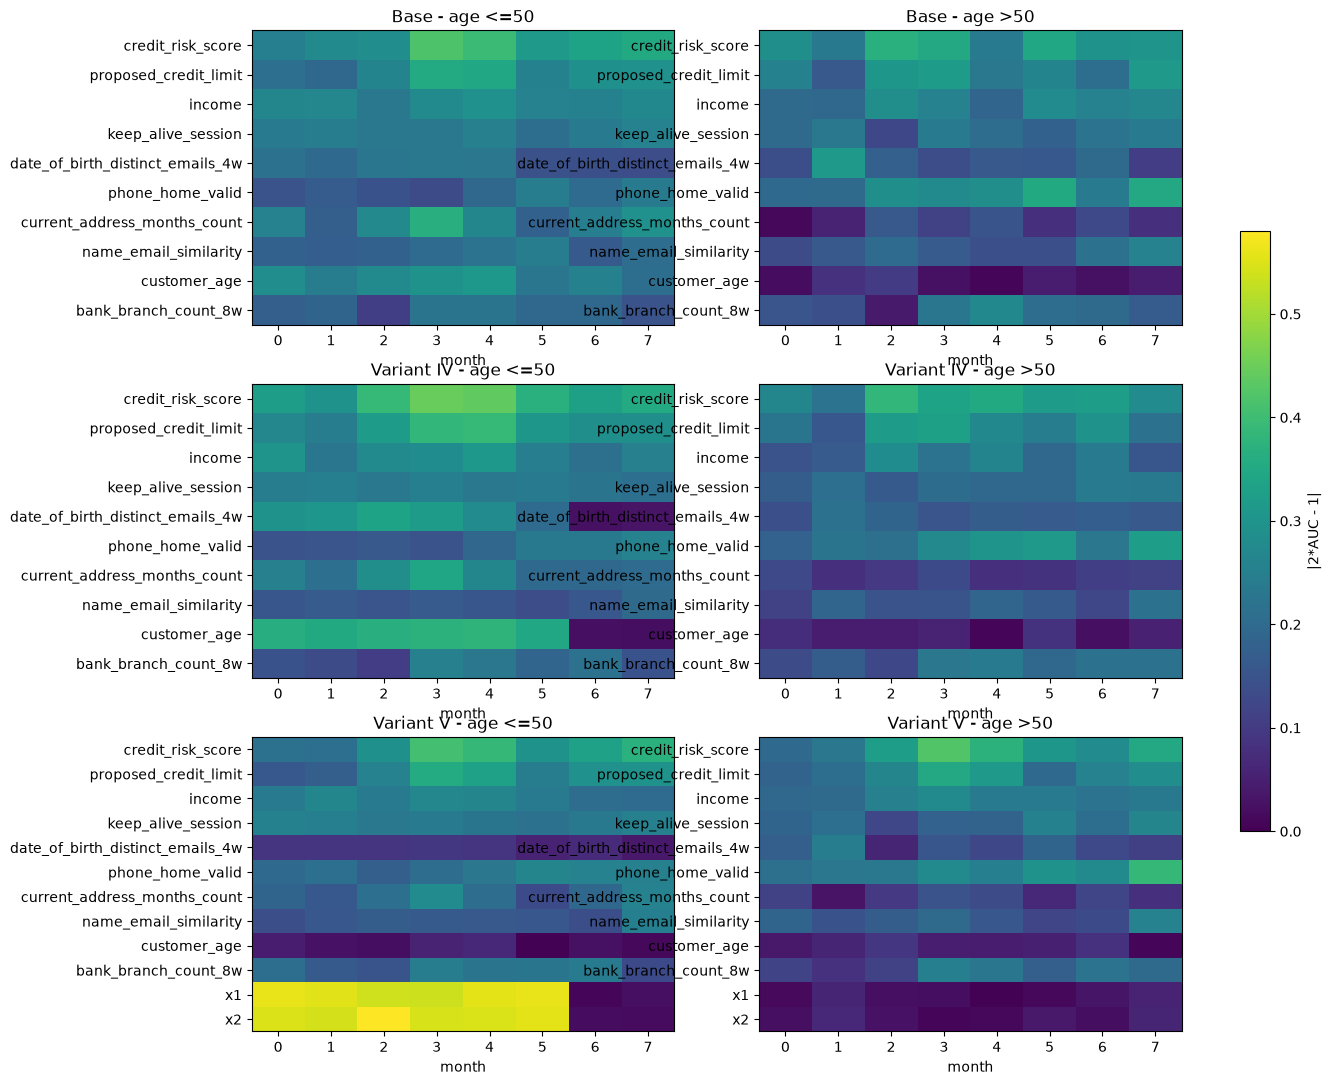

period                             months 0-5  months 6-7
dataset    feature      age_group                        
Base       customer_age <=50           0.2730      0.2330
                        >50            0.0470      0.0350
Variant IV customer_age <=50           0.3630      0.0220
                        >50            0.0530      0.0390
Variant V  customer_age <=50           0.0370      0.0190
                        >50            0.0570      0.0450
           x1           <=50           0.5520      0.0160
                        >50            0.0230      0.0460
           x2           <=50           0.5540      0.0190
                        >50            0.0300      0.0400

In [28]:
strength_rows = []
for dataset, df in datasets.items():
    train = df[df["split"] == "train"]
    # use each dataset's own columns, otherwise Variant V's x1/x2 get left out
    num_features = [c for c in df.columns
                    if c not in CAT_COLS + [TARGET, MONTH, "age_group", "split"]
                    and train[c].nunique(dropna=False) > 1]
    for (month, age_group), month_group in df.groupby([MONTH, "age_group"]):
        if month_group[TARGET].nunique() < 2:
            continue
        for col in num_features:
            values = month_group[col].fillna(month_group[col].median())
            auc = roc_auc_score(month_group[TARGET], values)
            strength_rows.append({"month": month, "age_group": age_group, "feature": col,
                                  "strength": abs(2 * auc - 1), "dataset": dataset})
strength = pd.DataFrame(strength_rows)
strength.to_csv(OUT_DIR + "/feature_strength.csv", index=False)

base_train_strength = strength[(strength["dataset"] == "Base") & (strength["month"].isin(TRAIN_MONTHS))]
top_feats = list(base_train_strength.groupby("feature")["strength"].mean().nlargest(10).index)
# the shifts are injected through these, so always show them even if they're not top 10 on Base
for col in ["customer_age", "x1", "x2"]:
    if col not in top_feats:
        top_feats.append(col)

fig, axes = plt.subplots(3, 2, figsize=(15, 13))
for i, dataset in enumerate(datasets):
    for j, age_group in enumerate(["<=50", ">50"]):
        group_strength = strength[(strength["dataset"] == dataset) & (strength["age_group"] == age_group)
                                  & (strength["feature"].isin(top_feats))]
        heat = (group_strength.pivot(index="feature", columns="month", values="strength")
                .reindex(top_feats).dropna(how="all"))
        im = axes[i, j].imshow(heat.values, aspect="auto", cmap="viridis", vmin=0, vmax=strength["strength"].max())
        axes[i, j].set_title(dataset + " - age " + age_group)
        axes[i, j].set_xticks(range(heat.shape[1]))
        axes[i, j].set_xticklabels(heat.columns)
        axes[i, j].set_yticks(range(len(heat)))
        axes[i, j].set_yticklabels(heat.index)
        axes[i, j].set_xlabel("month")
fig.colorbar(im, ax=axes, shrink=0.6, label="|2*AUC - 1|")
fig.savefig(OUT_DIR + "/fig4_feature_strength.png", dpi=200, bbox_inches="tight")
plt.show()

shift_feats = strength[strength["feature"].isin(["customer_age", "x1", "x2"])].copy()
shift_feats["period"] = np.where(shift_feats["month"].isin(TEST_MONTHS), "months 6-7", "months 0-5")
display(shift_feats.pivot_table(index=["dataset", "feature", "age_group"], columns="period", values="strength").round(3))

### 11.1b Feature distribution drift (PSI)
Section 11.1 measures how *predictive* each feature is. This checks whether the feature *values* themselves move between the training months (0–3) and the test months (6–7), using the Population Stability Index: < 0.1 stable, 0.1–0.25 moderate, > 0.25 large drift. Low PSI alongside a fall in predictive strength means the shift is in feature predictiveness, not feature distributions.

In [29]:
drift_rows = []
for dataset, df in datasets.items():
    train = df[df["split"] == "train"]
    test = df[df["split"] == "test"]
    features = [c for c in df.columns if c not in [TARGET, MONTH, "age_group", "split"]
                and train[c].nunique(dropna=False) > 1]
    for col in features:
        train_vals = train[col].dropna()
        test_vals = test[col].dropna()

        edges = []
        if col not in CAT_COLS:
            edges = np.unique(np.quantile(train_vals, np.linspace(0, 1, 11)))

        # binary / low-cardinality columns collapse to < 3 quantile edges, so compare value shares instead
        if len(edges) >= 3:
            expected = np.histogram(train_vals, edges)[0] / len(train_vals)
            actual = np.histogram(test_vals.clip(edges[0], edges[-1]), edges)[0] / len(test_vals)
        else:
            categories = np.union1d(train_vals.unique(), test_vals.unique())
            expected = train_vals.value_counts(normalize=True).reindex(categories, fill_value=0).values
            actual = test_vals.value_counts(normalize=True).reindex(categories, fill_value=0).values

        # avoid log(0) for bins that are empty in one period
        expected = np.clip(expected, 1e-6, None)
        actual = np.clip(actual, 1e-6, None)
        psi = np.sum((actual - expected) * np.log(actual / expected))
        drift_rows.append({"feature": col, "dataset": dataset, "psi": psi})

drift = pd.DataFrame(drift_rows).pivot(index="feature", columns="dataset", values="psi")
display(drift.sort_values("Base", ascending=False).round(3))
for dataset in datasets:
    print(dataset, "- features with PSI > 0.1:", list(drift.index[drift[dataset] > 0.1]))
drift.to_csv(OUT_DIR + "/feature_drift_psi.csv")

dataset,Base,Variant IV,Variant V
feature,,,
velocity_4w,4.3170,4.1230,4.1200
velocity_24h,2.0960,1.8630,1.8530
velocity_6h,1.2480,1.0610,1.0570
zip_count_4w,0.5430,0.4350,0.4360
date_of_birth_distinct_emails_4w,0.5310,0.2800,0.2880
credit_risk_score,0.3240,0.2710,0.2680
prev_address_months_count,0.1320,0.1110,0.1200
income,0.0970,0.0990,0.0980
proposed_credit_limit,0.0930,0.0880,0.0870


Base - features with PSI > 0.1: ['credit_risk_score', 'date_of_birth_distinct_emails_4w', 'prev_address_months_count', 'velocity_24h', 'velocity_4w', 'velocity_6h', 'zip_count_4w']
Variant IV - features with PSI > 0.1: ['credit_risk_score', 'date_of_birth_distinct_emails_4w', 'prev_address_months_count', 'velocity_24h', 'velocity_4w', 'velocity_6h', 'zip_count_4w']
Variant V - features with PSI > 0.1: ['credit_risk_score', 'date_of_birth_distinct_emails_4w', 'prev_address_months_count', 'velocity_24h', 'velocity_4w', 'velocity_6h', 'zip_count_4w']


### 11.2 Permutation importance (selected model): validation vs test
Importance is measured as the drop in AP when a feature is shuffled, on a sample of each period. Features that matter on validation but not on test indicate reliance on unstable relationships.

In [30]:
PI_SAMPLE = 50000   # permutation importance on the full 250k rows per period is too slow
pi_rows = []
for dataset, df in datasets.items():
    pipe, features = fitted[(dataset, BEST)]
    for split in ["val", "test"]:
        period_df = df[df["split"] == split]
        period_df = period_df.sample(min(PI_SAMPLE, len(period_df)), random_state=RANDOM_STATE)
        perm = permutation_importance(pipe, period_df[features], period_df[TARGET], scoring="average_precision",
                                      n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
        for feature, importance in zip(features, perm.importances_mean):
            pi_rows.append({"dataset": dataset, "split": split, "feature": feature, "importance": importance})

pi = pd.DataFrame(pi_rows).pivot_table(index=["dataset", "feature"], columns="split", values="importance")
pi["change"] = pi["test"] - pi["val"]
for dataset in datasets:
    print("\n" + dataset + " - top 10 features by validation importance (" + BEST + ")")
    display(pi.loc[dataset].sort_values("val", ascending=False).head(10))
pi.to_csv(OUT_DIR + "/permutation_importance.csv")


Base - top 10 features by validation importance (XGBoost)


split,test,val,change
feature,,,
device_os,0.0357,0.0385,-0.0027
has_other_cards,0.0189,0.0318,-0.0129
housing_status,0.0445,0.0308,0.0137
phone_home_valid,0.0349,0.0258,0.0091
proposed_credit_limit,0.0129,0.0219,-0.0090
name_email_similarity,0.0245,0.0213,0.0032
credit_risk_score,0.0167,0.0196,-0.0029
current_address_months_count,0.0112,0.0151,-0.0039
customer_age,0.0108,0.0143,-0.0035



Variant IV - top 10 features by validation importance (XGBoost)


split,test,val,change
feature,,,
device_os,0.0265,0.0370,-0.0104
housing_status,0.0194,0.0298,-0.0104
customer_age,-0.0072,0.0265,-0.0337
phone_home_valid,0.0245,0.0201,0.0044
has_other_cards,0.0140,0.0198,-0.0057
keep_alive_session,0.0139,0.0196,-0.0057
credit_risk_score,0.0120,0.0174,-0.0054
proposed_credit_limit,0.0102,0.0165,-0.0062
date_of_birth_distinct_emails_4w,0.0037,0.0163,-0.0126



Variant V - top 10 features by validation importance (XGBoost)


split,test,val,change
feature,,,
x1,0.0013,0.3384,-0.3370
x2,-0.0064,0.3295,-0.3359
customer_age,-0.0032,0.0633,-0.0665
phone_home_valid,0.0193,0.0280,-0.0087
has_other_cards,0.0112,0.0239,-0.0127
device_os,0.0194,0.0191,0.0003
current_address_months_count,0.0061,0.0151,-0.0090
name_email_similarity,0.0084,0.0147,-0.0062
income,0.0090,0.0137,-0.0048


### 11.3 Error analysis: frauds missed in the test period
Using the selected model at the fixed threshold, test-period frauds are split into caught vs missed, by age group, and their feature profiles are compared.

In [31]:
error_by_age = []
error_profiles = []
for dataset, df in datasets.items():
    test_frauds = preds[(preds["dataset"] == dataset) & (preds["model"] == BEST)
                        & (preds["split"] == "test") & (preds["y"] == 1)]
    print("\n=== " + dataset + " ===")
    caught = test_frauds.groupby("age_group")["flag_thr"].agg(frauds="size", caught="sum", recall="mean")
    display(caught)
    caught.insert(0, "dataset", dataset)
    error_by_age.append(caught.reset_index())

    fraud_profiles = df.loc[test_frauds["row"]].copy()
    fraud_profiles["outcome"] = np.where(test_frauds["flag_thr"].values, "caught", "missed")
    profile_cols = [c for c in top_feats if c in df.columns]
    profile = fraud_profiles.groupby(["age_group", "outcome"])[profile_cols].median()
    display(profile.T)
    profile.insert(0, "dataset", dataset)
    error_profiles.append(profile.reset_index())

pd.concat(error_by_age, ignore_index=True).to_csv(OUT_DIR + "/error_analysis_by_age.csv", index=False)
pd.concat(error_profiles, ignore_index=True).to_csv(OUT_DIR + "/error_analysis_profiles.csv", index=False)


=== Base ===


,frauds,caught,recall
age_group,,,
<=50,2519,1224,0.4859
>50,359,259,0.7214


age_group                             <=50                >50         
outcome                             caught   missed    caught   missed
credit_risk_score                 218.0000 161.0000  208.0000 144.5000
proposed_credit_limit            1000.0000 200.0000 1000.0000 200.0000
income                              0.9000   0.8000    0.9000   0.8000
keep_alive_session                  0.0000   0.0000    0.0000   0.0000
date_of_birth_distinct_emails_4w    6.0000   7.0000    2.0000   3.0000
phone_home_valid                    0.0000   0.0000    0.0000   1.0000
current_address_months_count      104.0000  77.0000  127.0000 122.0000
name_email_similarity               0.2402   0.3619    0.2072   0.3616
customer_age                       40.0000  30.0000   60.0000  60.0000
bank_branch_count_8w                1.0000   8.0000    2.0000  10.0000


=== Variant IV ===


,frauds,caught,recall
age_group,,,
<=50,2171,906,0.4173
>50,481,318,0.6611


age_group                             <=50               >50         
outcome                             caught   missed   caught   missed
credit_risk_score                 228.0000 170.0000 205.5000 156.0000
proposed_credit_limit            1250.0000 500.0000 990.0000 500.0000
income                              0.9000   0.8000   0.9000   0.7000
keep_alive_session                  0.0000   0.0000   0.0000   0.0000
date_of_birth_distinct_emails_4w    5.0000   7.0000   2.0000   3.0000
phone_home_valid                    0.0000   0.0000   0.0000   1.0000
current_address_months_count      108.5000  82.0000 125.5000 127.0000
name_email_similarity               0.2625   0.3381   0.2183   0.4438
customer_age                       50.0000  40.0000  60.0000  60.0000
bank_branch_count_8w                1.0000   7.0000   2.0000   9.0000


=== Variant V ===


,frauds,caught,recall
age_group,,,
<=50,2156,625,0.2899
>50,496,323,0.6512


age_group                             <=50                >50         
outcome                             caught   missed    caught   missed
credit_risk_score                 237.0000 182.0000  208.0000 152.0000
proposed_credit_limit            1500.0000 500.0000 1000.0000 200.0000
income                              0.9000   0.8000    0.9000   0.7000
keep_alive_session                  0.0000   0.0000    0.0000   0.0000
date_of_birth_distinct_emails_4w    5.0000   7.0000    2.0000   3.0000
phone_home_valid                    0.0000   0.0000    0.0000   1.0000
current_address_months_count      119.0000  94.0000  126.0000 113.0000
name_email_similarity               0.2272   0.3035    0.2411   0.2949
customer_age                       50.0000  40.0000   60.0000  60.0000
bank_branch_count_8w                1.0000   4.0000    2.0000   8.0000
x1                                  0.1887  -0.0600   -0.0996  -0.0315
x2                                  0.1631  -0.0928    0.0399  -0.0305

### 11.4 Ablation: remove the shifted features and retrain
A direct test of RQ2 within each variant (no comparison with Base needed). Variant IV is retrained without `customer_age`, Variant V without `x1` and `x2`, keeping the same hyperparameters. If the validation-to-test drop mostly disappears, that feature is what carried the shift. Results are split by age group for RQ3.

In [32]:
ablations = {"Variant IV": ["customer_age"], "Variant V": ["x1", "x2"]}
abl_models = ["Logistic Regression"]
if BEST != "Logistic Regression":
    abl_models.append(BEST)

abl_frames = []
for dataset, drop_cols in ablations.items():
    df = datasets[dataset]
    train = df[df["split"] == "train"].drop(columns=drop_cols)
    eval_df = df[df["split"] != "train"]
    for model_name in abl_models:
        pipe, features = train_model(train, model_name, best_params[model_name])
        scored = pd.DataFrame({"y": eval_df[TARGET].values, "split": eval_df["split"].values,
                               "age_group": eval_df["age_group"].values})
        scored["score"] = pipe.predict_proba(eval_df[features])[:, 1]
        # same tie-breaking as section 5, in case the selected model has tied scores
        scored["score_tb"] = scored["score"] + np.random.default_rng(RANDOM_STATE).uniform(0, 1e-9, len(scored))

        overall = scored.groupby("split").apply(rank_scores).reset_index()
        overall["age_group"] = "all"
        per_age = scored.groupby(["split", "age_group"]).apply(rank_scores).reset_index()

        abl_metrics = pd.concat([overall, per_age])
        abl_metrics["dataset"] = dataset
        abl_metrics["model"] = model_name
        abl_metrics["dropped"] = "+".join(drop_cols)
        abl_frames.append(abl_metrics)
        print(dataset, "-", model_name, "without", drop_cols, "done")
abl = pd.concat(abl_frames, ignore_index=True)
abl["features"] = "shift features removed"

full_preds = preds[preds["dataset"].isin(list(ablations)) & preds["model"].isin(abl_models)]
full_overall = full_preds.groupby(["dataset", "model", "split"]).apply(rank_scores).reset_index()
full_overall["age_group"] = "all"
full_per_age = full_preds.groupby(["dataset", "model", "split", "age_group"]).apply(rank_scores).reset_index()
full_metrics = pd.concat([full_overall, full_per_age])
full_metrics["features"] = "all"

ablation_results = pd.concat([full_metrics, abl], ignore_index=True)
recall_table = ablation_results.pivot_table(index=["dataset", "model", "age_group", "features"],
                                            columns="split", values="recall@5%FPR")
recall_table["change"] = recall_table["test"] - recall_table["val"]
display(recall_table.round(3))
ablation_results.to_csv(OUT_DIR + "/ablation.csv", index=False)

Variant IV - Logistic Regression without ['customer_age'] done


Variant IV - XGBoost without ['customer_age'] done


Variant V - Logistic Regression without ['x1', 'x2'] done


Variant V - XGBoost without ['x1', 'x2'] done


split                                                             test    val  \
dataset    model               age_group features                               
Variant IV Logistic Regression <=50      all                    0.4000 0.5170   
                                         shift features removed 0.4320 0.4980   
                               >50       all                    0.4160 0.4290   
                                         shift features removed 0.3970 0.4350   
                               all       all                    0.4050 0.5190   
                                         shift features removed 0.4290 0.4960   
           XGBoost             <=50      all                    0.4480 0.5680   
                                         shift features removed 0.4840 0.5550   
                               >50       all                    0.4410 0.4750   
                                         shift features removed 0.4390 0.4730   
                               all       all                    0.4530 0.5660   
                                         shift features removed 0.4720 0.5490   
Variant V  Logistic Regression <=50      all                    0.3320 0.7030   
                                         shift features removed 0.4730 0.4710   
                               >50       all                    0.3590 0.2980   
                                         shift features removed 0.4480 0.4210   
                               all       all                    0.3470 0.6430   
                                         shift features removed 0.4720 0.4650   
           XGBoost             <=50      all                    0.3440 0.8070   
                                         shift features removed 0.5240 0.5220   
                               >50       all                    0.4600 0.4400   
                                         shift features removed 0.4560 0.4580   
                               all       all                    0.3720 0.7620   
                                         shift features removed 0.5170 0.5180   

split                                                            change  
dataset    model               age_group features                        
Variant IV Logistic Regression <=50      all                    -0.1170  
                                         shift features removed -0.0660  
                               >50       all                    -0.0130  
                                         shift features removed -0.0380  
                               all       all                    -0.1140  
                                         shift features removed -0.0660  
           XGBoost             <=50      all                    -0.1210  
                                         shift features removed -0.0710  
                               >50       all                    -0.0340  
                                         shift features removed -0.0340  
                               all       all                    -0.1130  
                                         shift features removed -0.0770  
Variant V  Logistic Regression <=50      all                    -0.3710  
                                         shift features removed  0.0020  
                               >50       all                     0.0610  
                                         shift features removed  0.0260  
                               all       all                    -0.2960  
                                         shift features removed  0.0070  
           XGBoost             <=50      all                    -0.4640  
                                         shift features removed  0.0020  
                               >50       all                     0.0190  
                                         shift features removed -0.0020  
                               all       all                    -0.3900  
                                         sh

### 11.5 Retraining on more recent months
Would a bank that retrains more often have avoided the loss? Logistic regression and the selected model are retrained on months 0–5 (all labelled history) and on months 2–5 (recent only), with the same hyperparameters, and scored on the same test months 6–7. Ranking metrics are used because no validation months are left to set a threshold. In Variant V the shift starts in month 6, so retraining can only help if the shift is already visible in the training labels.

In [33]:
TRAIN_WINDOWS = {"months 0-5": [0, 1, 2, 3, 4, 5], "months 2-5": [2, 3, 4, 5]}

retrain_rows = []
# original models (months 0-3) from section 5, for comparison
orig_test = preds[(preds["split"] == "test") & preds["model"].isin(focus_models)]
for (dataset, model_name), model_test in orig_test.groupby(["dataset", "model"]):
    for age_group, group in [("all", model_test)] + list(model_test.groupby("age_group")):
        retrain_rows.append({"dataset": dataset, "model": model_name, "train_months": "months 0-3",
                             "age_group": age_group, **rank_scores(group).to_dict()})

for dataset, df in datasets.items():
    test = df[df["split"] == "test"]
    for window, months in TRAIN_WINDOWS.items():
        train = df[df[MONTH].isin(months)]
        for model_name in focus_models:
            pipe, features = train_model(train, model_name, best_params[model_name])
            scored = pd.DataFrame({"y": test[TARGET].values, "age_group": test["age_group"].values,
                                   "score": pipe.predict_proba(test[features])[:, 1]})
            # same tie-breaking as section 5, in case the selected model has tied scores
            scored["score_tb"] = scored["score"] + np.random.default_rng(RANDOM_STATE).uniform(0, 1e-9, len(scored))
            for age_group, group in [("all", scored)] + list(scored.groupby("age_group")):
                retrain_rows.append({"dataset": dataset, "model": model_name, "train_months": window,
                                     "age_group": age_group, **rank_scores(group).to_dict()})
            print(dataset, "-", model_name, "trained on", window, "done")
retraining = pd.DataFrame(retrain_rows)

display(retraining.pivot_table(index=["dataset", "model", "age_group"], columns="train_months",
                               values="recall@5%FPR").round(3))
retraining.to_csv(OUT_DIR + "/retraining.csv", index=False)

Base - Logistic Regression trained on months 0-5 done


Base - XGBoost trained on months 0-5 done


Base - Logistic Regression trained on months 2-5 done


Base - XGBoost trained on months 2-5 done


Variant IV - Logistic Regression trained on months 0-5 done


Variant IV - XGBoost trained on months 0-5 done


... (3 outputs left out)

Variant V - XGBoost trained on months 0-5 done


Variant V - Logistic Regression trained on months 2-5 done


Variant V - XGBoost trained on months 2-5 done


train_months                              months 0-3  months 0-5  months 2-5
dataset    model               age_group                                    
Base       Logistic Regression <=50           0.4800      0.4890      0.4920
                               >50            0.4260      0.4430      0.4370
                               all            0.4970      0.5050      0.5100
           XGBoost             <=50           0.5350      0.5420      0.5400
                               >50            0.4790      0.4760      0.4680
                               all            0.5430      0.5530      0.5460
Variant IV Logistic Regression <=50           0.4000      0.4020      0.4030
                               >50            0.4160      0.4070      0.4140
                               all            0.4050      0.4080      0.4070
           XGBoost             <=50           0.4480      0.4450      0.4420
                               >50            0.4410      0.4470      0.4410
                               all            0.4530      0.4480      0.4430
Variant V  Logistic Regression <=50           0.3320      0.3390      0.3460
                               >50            0.3590      0.3670      0.3750
                               all            0.3470      0.3520      0.3560
           XGBoost             <=50           0.3440      0.3440      0.3280
                               >50            0.4600      0.4660      0.4560
                               all            0.3720      0.3730      0.3650

## 12. Summary table
One row per dataset × model with the headline numbers for the report.

In [34]:
summary = robust[["AP_val", "AP_test", "AP_change", "recall@5%FPR_val", "recall@5%FPR_test", "recall@5%FPR_change"]].copy()

thr_test = thr_period[thr_period["split"] == "test"].set_index(["dataset", "model"])
summary["thr_test_recall"] = thr_test["recall"]
summary["thr_test_FPR"] = thr_test["FPR"]
summary["thr_test_alert_rate"] = thr_test["alert_rate"]

age_test = gap_thr.xs("test", level="split")
summary["age_test_FPR_ratio_>50/<=50"] = age_test["FPR_ratio_>50/<=50"]
summary["age_test_recall_diff_>50-<=50"] = age_test["recall_diff_>50-<=50"]

for cap in REVIEW_CAPACITIES:
    cap_test = cap_period[(cap_period["capacity"] == cap) & (cap_period["split"] == "test")].set_index(["dataset", "model"])
    summary["cap" + str(int(cap * 100)) + "_test_recall"] = cap_test["recall"]

display(summary)
summary.to_csv(OUT_DIR + "/summary.csv")

AP_val  AP_test  AP_change  recall@5%FPR_val  \
dataset    model                                                               
Base       Decision Tree        0.0956   0.1060     0.0104            0.4275   
           LightGBM             0.1904   0.1963     0.0059            0.5620   
           Logistic Regression  0.1446   0.1604     0.0158            0.5169   
           Random Forest        0.1456   0.1645     0.0190            0.5176   
           XGBoost              0.1915   0.1960     0.0045            0.5606   
Variant IV Decision Tree        0.0997   0.0577    -0.0419            0.4353   
           LightGBM             0.1961   0.1173    -0.0787            0.5662   
           Logistic Regression  0.1612   0.0939    -0.0673            0.5190   
           Random Forest        0.1600   0.0888    -0.0712            0.5217   
           XGBoost              0.1966   0.1168    -0.0798            0.5659   
Variant V  Decision Tree        0.3931   0.0402    -0.3529            0.6315   
           LightGBM             0.5509   0.0762    -0.4748            0.7662   
           Logistic Regression  0.3525   0.0693    -0.2831            0.6426   
           Random Forest        0.5024   0.0715    -0.4309            0.7187   
           XGBoost              0.5377   0.0838    -0.4539            0.7620   

                                recall@5%FPR_test  recall@5%FPR_change  \
dataset    model                                                         
Base       Decision Tree                   0.4124              -0.0151   
           LightGBM                        0.5455              -0.0165   
           Logistic Regression             0.4965              -0.0204   
           Random Forest                   0.5174              -0.0003   
           XGBoost                         0.5434              -0.0172   
Variant IV Decision Tree                   0.3190              -0.1163   
           LightGBM                        0.4472              -0.1190   
           Logistic Regression             0.4046              -0.1144   
           Random Forest                   0.3854              -0.1363   
           XGBoost                         0.4532              -0.1126   
Variant V  Decision Tree                   0.2896              -0.3419   
           LightGBM                        0.3620              -0.4043   
           Logistic Regression             0.3469              -0.2957   
           Random Forest                   0.3612              -0.3575   
           XGBoost                         0.3718              -0.3902   

                                thr_test_recall  thr_test_FPR  \
dataset    model                                                
Base       Decision Tree                 0.3853        0.0433   
           LightGBM                      0.5087        0.0414   
           Logistic Regression           0.4051        0.0322   
           Random Forest                 0.4413        0.0358   
           XGBoost                       0.5153        0.0441   
Variant IV Decision Tree                 0.3047        0.0484   
           LightGBM                      0.4453        0.0496   
           Logistic Regression           0.3522        0.0391   
           Random Forest                 0.3518        0.0416   
           XGBoost                       0.4615        0.0528   
Variant V  Decision Tree                 0.2821        0.0487   
           LightGBM                      0.3360        0.0442   
           Logistic Regression           0.2885        0.0384   
           Random Forest                 0.3299        0.0427   
           XGBoost                       0.3575        0.0459   

                                thr_test_alert_rate  \
dataset    model                                      
Base       Decision Tree                     0.0481   
           LightGBM                          0.0479   
           Logistic Regression               0.0375   
           Random Forest       

## Notes and limitations
* Scores are tie-broken with negligible random noise before thresholding (see section 5), so fixed-FPR and top-k rules behave sensibly for models with few distinct scores such as the decision tree.
* LightGBM runs in deterministic mode and both boosting libraries use a fixed thread count (`N_THREADS`), so re-runs on the same machine give identical results; different machines or library versions can still differ slightly. The imports cell prints the library versions used.
* The BAF data are synthetic; results are controlled evidence about model behaviour under imbalance and temporal shift, not production performance estimates.
* The model used for testing is the one trained on months 0–3, so the validation-chosen threshold matches its scores exactly. Refitting on months 0–5 would use more data but would require re-deriving the threshold (e.g. by cross-fitting).
* Hyperparameters were chosen by Optuna on a single time-respecting holdout (months 4–5 of Base); an expanding-window scheme is a possible extension.